# Stock 10: a clue that flips, a hidden wave, and a test row that breaks the pattern

Stock 10 is the biggest dataset so far (120,000 rows, 25 clues and 3 group columns). The price is built from **many small recipes**, and most of them are invisible to a normal correlation check:

1. a clue whose effect **flips direction** depending on the `mode`
2. **team effects**: clues that only matter together
3. **switches**: effects that turn on above a cut-off, or that grow in steps
4. a **hidden wave** in `x25`, a clue whose correlation with the price is exactly 0.00
5. a **test row** whose clues each look normal, but whose combination is unlike any training row

The goal is to find the **true formula** behind the price, not just the lowest score.

### The plan

| Part | What we do |
|---|---|
| 1 | Load the data and run a health check |
| 2 | Look at the data: groups, correlations, links between clues, the test row |
| 3 | Find the formula, one ingredient at a time |
| 4 | Test 12 models, including a **stress test** on the most unusual rows |
| 5 | Look inside the final formula |
| 6 | Measure how sure we are, and what other teams will say |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column used to predict the price: `x1`–`x25`, plus the groups `prefix`, `mode` and `tier`. |
| **Prefix** | The first 3 letters of the ticker (e.g. `WXM` in `WXM-7382B`). |
| **Leftover** | Real price minus what a model predicts: the part the model hasn't explained yet. |
| **Ingredient** | One piece of the price formula, e.g. `8 × x11`. |
| **Team effect** (= interaction) | Two clues that change the price **together**, e.g. through `x3 × x4`. |
| **Switch** (= threshold) | An effect that only turns on above a cut-off, e.g. only when `x5 > 0`. |
| **Wave** | An effect that goes up and down again and again, like a sine curve. |
| **Pattern distance** (= Mahalanobis distance) | How unusual a row is when you look at all clues **together**, taking into account which clues normally move together. |
| **Stress test** | Train only on ordinary rows, then check how well a model predicts the most unusual rows. |
| **CV RMSE** | How many pounds a model is wrong by on rows it hasn't seen. Smaller is better. |

---
# Part 1: Load the data

### Step 1.1: Load the tools

**What this cell does:** loads the libraries. New this time: `SplineTransformer` (lets a straight-line model draw a smooth curve for each clue) and `minimize_scalar` (finds the best value of a single number).

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
from scipy import stats
from scipy.optimize import minimize_scalar

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, SplineTransformer, FunctionTransformer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the files

**What this cell does:** reads the training and test files and shows the first rows.

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_10_train.csv")
test = pd.read_csv(DATA_DIR / "stock_10_test.csv")

xs = [f"x{i}" for i in range(1, 26)]          # x1 ... x25
print("Training rows:", len(train), "   Columns:", train.shape[1])
display(train.head(3))
test

Training rows: 120000    Columns: 30


,uid,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x20,x21,x22,x23,x24,x25,ticker,mode,tier,price
0,d408687bb6,1.3366,1.8349,0.8975,0.4496,-0.2812,-1.5655,-0.2646,0.6839,-0.4443,...,-1.0713,0.0397,-0.0411,1.4530,-1.5383,494.9863,BHX-2253W,A,3,497.91
1,e8c5d39b1a,-0.0404,-1.2627,-0.0836,0.1213,1.4667,1.4805,2.8273,-1.9352,0.9501,...,1.5571,2.5278,0.1939,-0.2469,-1.2163,620.5035,VLV-8566B,B,4,560.93
2,c946dcb3c8,-0.0660,1.5125,0.5433,-0.6565,-0.2450,-0.3912,-0.2891,0.9333,-1.0594,...,-0.8422,0.1001,1.1420,0.0260,-0.1947,727.7244,JCP-7627G,A,2,550.25


,id,uid,x1,x2,x3,x4,x5,x6,x7,x8,...,x19,x20,x21,x22,x23,x24,x25,ticker,mode,tier
0,stock_10,b45eb481fc,0.5994,0.5033,1.0992,-0.9003,0.4014,-1.2853,-1.5917,0.1983,...,0.9521,0.7368,-1.0593,1.1875,0.6348,0.6338,468.0906,WXM-7382B,B,4


**How to read the output:** 120,000 training rows. Each row has an ID (`uid`), 25 number clues (`x1`–`x25`), a `ticker`, a `mode` (A, B or C), a `tier` (1–5) and the `price`. The test row is ticker **WXM-7382B**, mode **B**, tier **4**.

### Step 1.3: Health check

**What this cell does:** counts empty cells and repeated rows, and summarises the price.

In [3]:
print("Empty cells:", train.isna().sum().sum())
print("Repeated rows:", train.duplicated().sum(), "   Repeated uids:", train["uid"].duplicated().sum())
train["price"].describe().round(2)

Empty cells: 0


Repeated rows: 0    Repeated uids: 0


count    120000.00
mean        522.92
std          34.84
min         331.64
25%         500.17
50%         523.61
75%         546.34
max         680.27
Name: price, dtype: float64

**How to read the output:** nothing is empty and nothing is repeated. Prices average about **£523**, with a spread (std) of about **£35**, from about £332 to £680.

### Step 1.4: Split the ticker into parts

A ticker like `WXM-7382B` has three parts: a **prefix** (`WXM`), a **number** (`7382`) and a **letter** (`B`). Each part could carry information, so we split them into separate columns.

**What this cell does:** splits the tickers and checks whether the test ticker, or its parts, appear in training.

In [4]:
for d in (train, test):
    parts = d["ticker"].str.extract(r"^([A-Z]{3})-(\d{4})([A-Z])$")
    d["prefix"], d["ticker_number"], d["ticker_letter"] = parts[0], parts[1].astype(int), parts[2]

prefixes = sorted(train["prefix"].unique())
print("Different tickers:", train["ticker"].nunique(), "   prefixes:", len(prefixes), "   letters:", train["ticker_letter"].nunique())
print("Test ticker seen in training?", bool(test["ticker"].isin(train["ticker"]).item()))
print("Training rows with the test prefix (WXM):", (train["prefix"] == "WXM").sum())

Different tickers: 116643    prefixes: 15    letters: 22
Test ticker seen in training? False
Training rows with the test prefix (WXM): 13019


**How to read the output:** almost every row has its own ticker, so the full ticker can't be learned. But there are only **15 prefixes**, and the test prefix **WXM** has about 13,000 training rows. The test ticker itself is new, which doesn't matter if only the prefix counts (Step 2.1 checks).

> **✅ Checkpoint.** 120,000 clean rows. The ticker is split into prefix, number and letter.

---
# Part 2: Look at the data

### Step 2.1: Do the groups matter?

**What this cell does:** draws the average price for each prefix, mode, tier and ticker letter. The test row's group is in red.

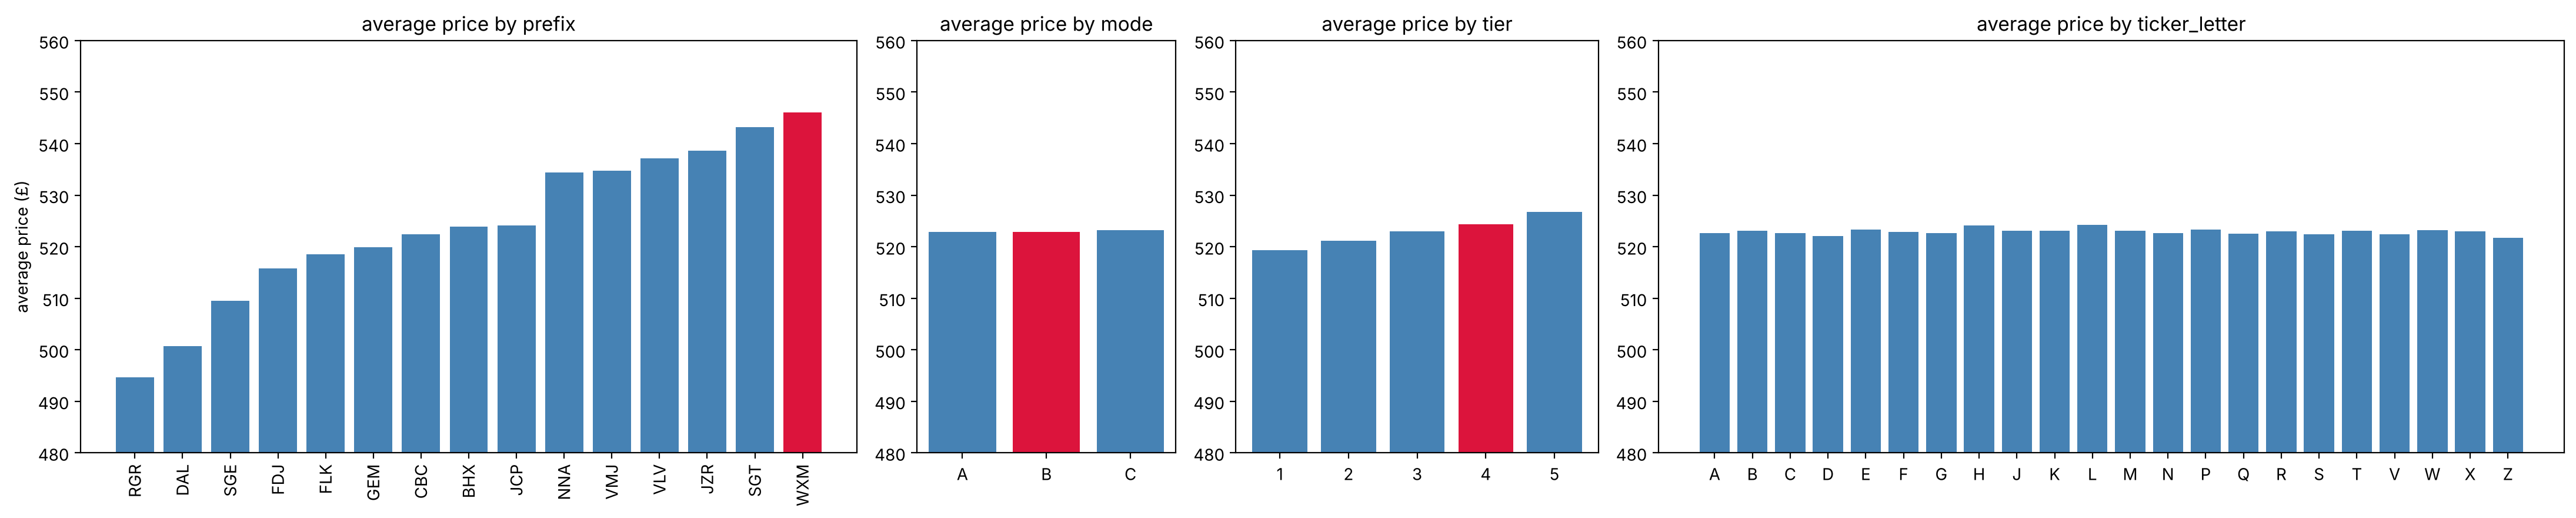

Gap between highest and lowest prefix average: £51.4
Gap between highest and lowest mode average:   £0.4
Gap between highest and lowest tier average:   £7.5
Gap between highest and lowest letter average: £2.5
Gap across 10 slices of the ticker number:     £1.2


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5), gridspec_kw={"width_ratios": [3, 1, 1.4, 3.5]})
for ax, group in zip(axes, ["prefix", "mode", "tier", "ticker_letter"]):
    means = train.groupby(group)["price"].mean()
    if group == "prefix":
        means = means.sort_values()
    test_value = test[group].item() if group != "ticker_letter" else None
    ax.bar(means.index.astype(str), means.values, color=["crimson" if v == test_value else "steelblue" for v in means.index])
    ax.set_ylim(480, 560)
    ax.set_title(f"average price by {group}")
    ax.tick_params(axis="x", rotation=90 if group == "prefix" else 0)
axes[0].set_ylabel("average price (£)")
plt.tight_layout()
plt.show()

number_slices = train.groupby(pd.qcut(train["ticker_number"], 10), observed=True)["price"].mean()
print(f"Gap between highest and lowest prefix average: £{train.groupby('prefix')['price'].mean().agg(np.ptp):.1f}")
print(f"Gap between highest and lowest mode average:   £{train.groupby('mode')['price'].mean().agg(np.ptp):.1f}")
print(f"Gap between highest and lowest tier average:   £{train.groupby('tier')['price'].mean().agg(np.ptp):.1f}")
print(f"Gap between highest and lowest letter average: £{train.groupby('ticker_letter')['price'].mean().agg(np.ptp):.1f}")
print(f"Gap across 10 slices of the ticker number:     £{np.ptp(number_slices):.1f}")

**How to read the output**

* **Prefix matters a lot**: about £51 between the cheapest (`DAL`, `RGR`) and the dearest (`WXM`, the test prefix).
* **Tier** rises gently from 1 to 5 (about £7.5).
* **Mode** barely changes the average (less than £1). Careful: a group can still matter even if its average doesn't move. Step 3.3 shows mode is very important.
* The **ticker letter** and the **ticker number** move the average by only about £2.5 and £1.2, which is just noise, so we won't use them.

### Step 2.2: Which clues move the price?

**What this cell does:** shows each clue's correlation with the price.

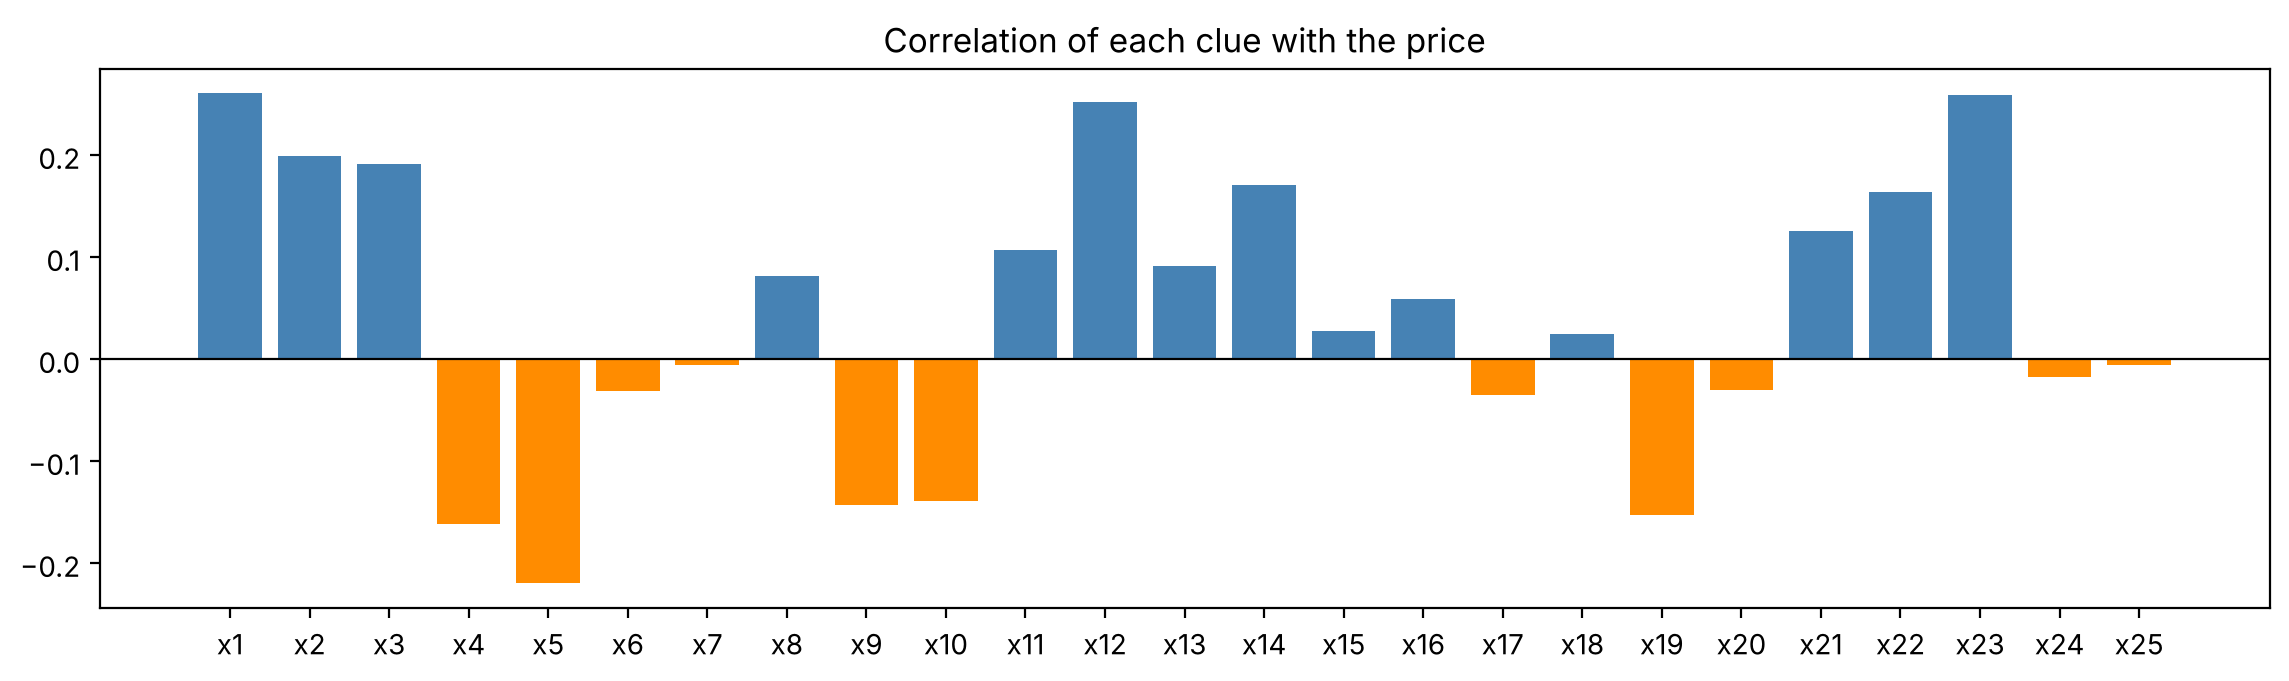

Strongest: {'x1': 0.261, 'x23': 0.259, 'x12': 0.252, 'x5': 0.22, 'x2': 0.199}
x25: -0.005


In [6]:
corr_with_price = train[xs].corrwith(train["price"])
plt.figure(figsize=(14, 3.5))
plt.bar(corr_with_price.index, corr_with_price.values, color=["steelblue" if v > 0 else "darkorange" for v in corr_with_price])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Correlation of each clue with the price")
plt.show()
print("Strongest:", corr_with_price.abs().sort_values(ascending=False).head(5).round(3).to_dict())
print(f"x25: {corr_with_price['x25']:.3f}")

**How to read the output:** the strongest correlations are only about **0.2–0.26** (`x1`, `x23`, `x12`, `x5`, `x2`). Eight clues, including `x25`, show about **0**. Correlation only sees **straight lines**, so a clue with a curved, flipping or wavy effect can show 0 and still matter. Part 3 finds several of those.

### Step 2.3: Links between clues

**What this cell does:** draws the correlation between every pair of clues. Red = they go up together, blue = one goes up when the other goes down.

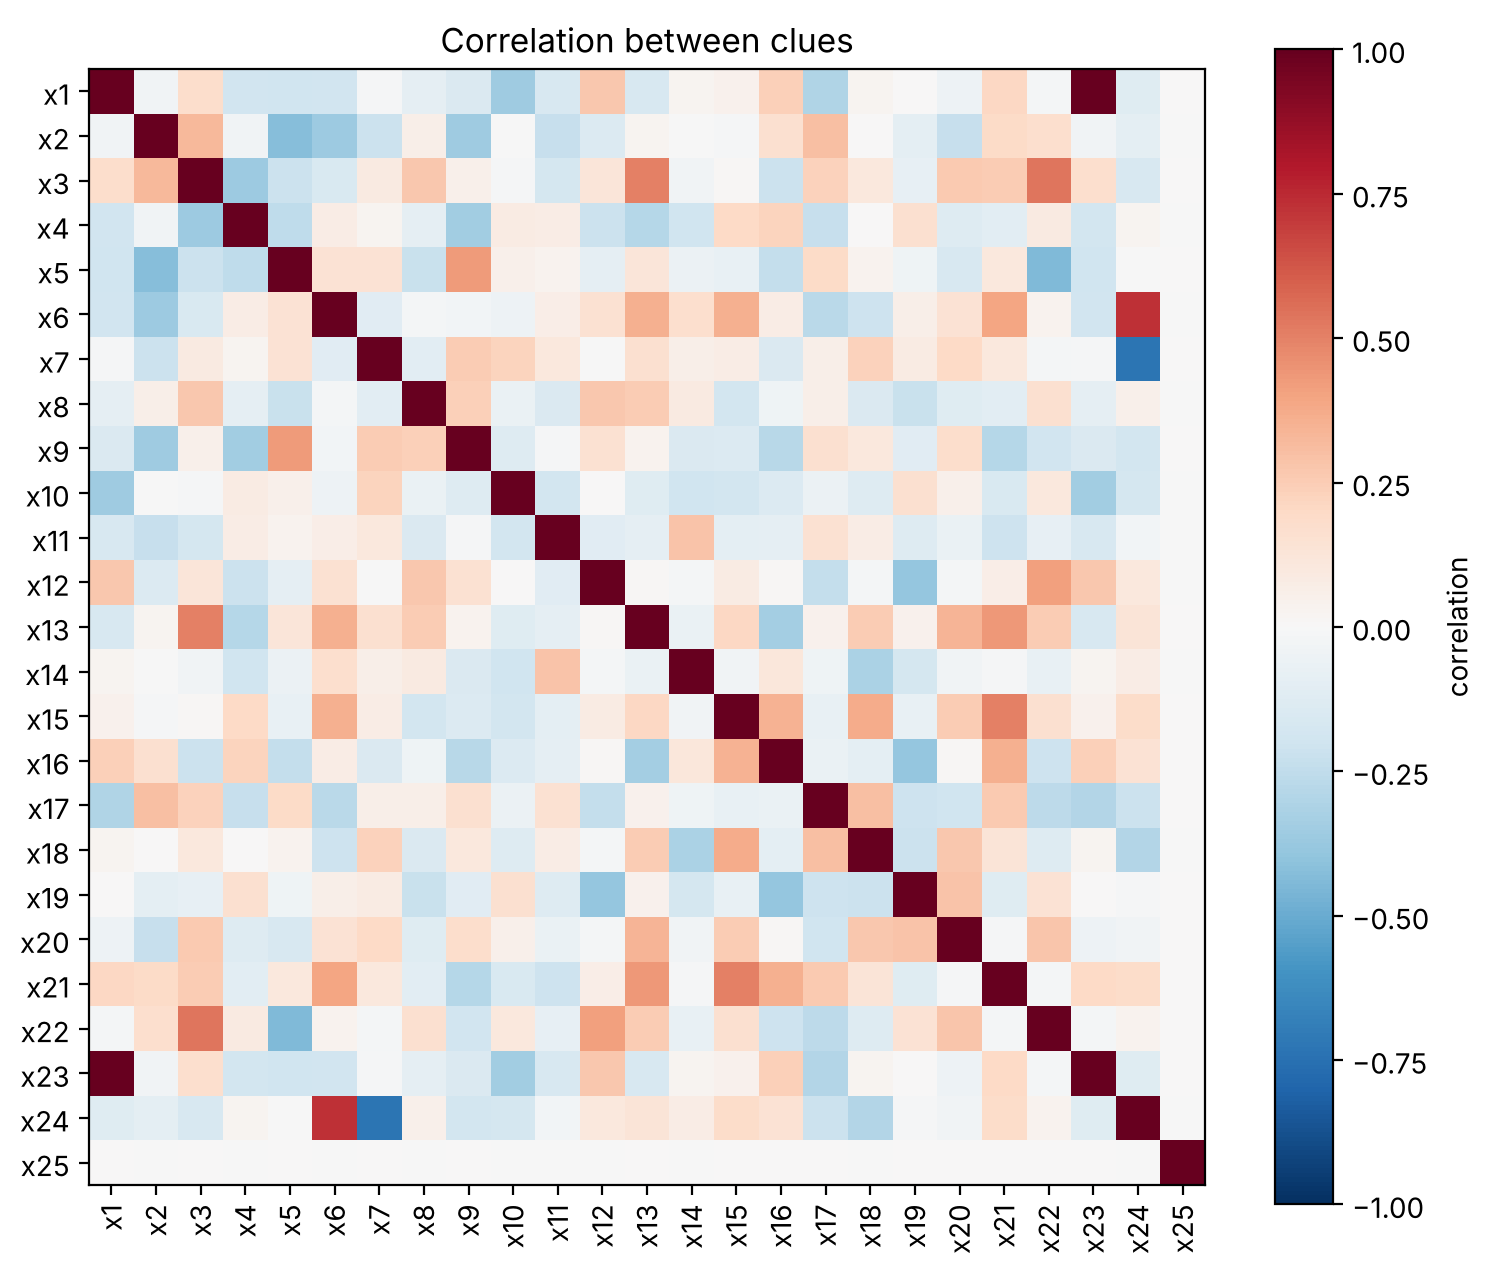

Strongest pairs:
x1   x23    0.995
x6   x24    0.732
x7   x24    0.730
x3   x22    0.536
     x13    0.504
x15  x21    0.501


In [7]:
clue_corr = train[xs].corr()
plt.figure(figsize=(9, 7.5))
plt.imshow(clue_corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(25), xs, rotation=90); plt.yticks(range(25), xs)
plt.title("Correlation between clues")
plt.show()

pairs = clue_corr.where(np.triu(np.ones((25, 25), dtype=bool), 1)).stack()
print("Strongest pairs:")
print(pairs.abs().sort_values(ascending=False).head(6).round(3).to_string())

**How to read the output**

* **x1 and x23** correlate at **0.995**: x23 is a near-copy of x1.
* **x24** correlates with **x6 (+0.73)** and **x7 (−0.73)**: it looks like x6 − x7.
* Many other clues are moderately linked (about 0.2–0.5), so the clues in `x1`–`x22` are tangled together.
* **x25** is linked to nothing.

### Step 2.4: The near-copies, and x25

**What this cell does:** plots x23 against x1, x24 against x6 − x7, and the spread of x25.

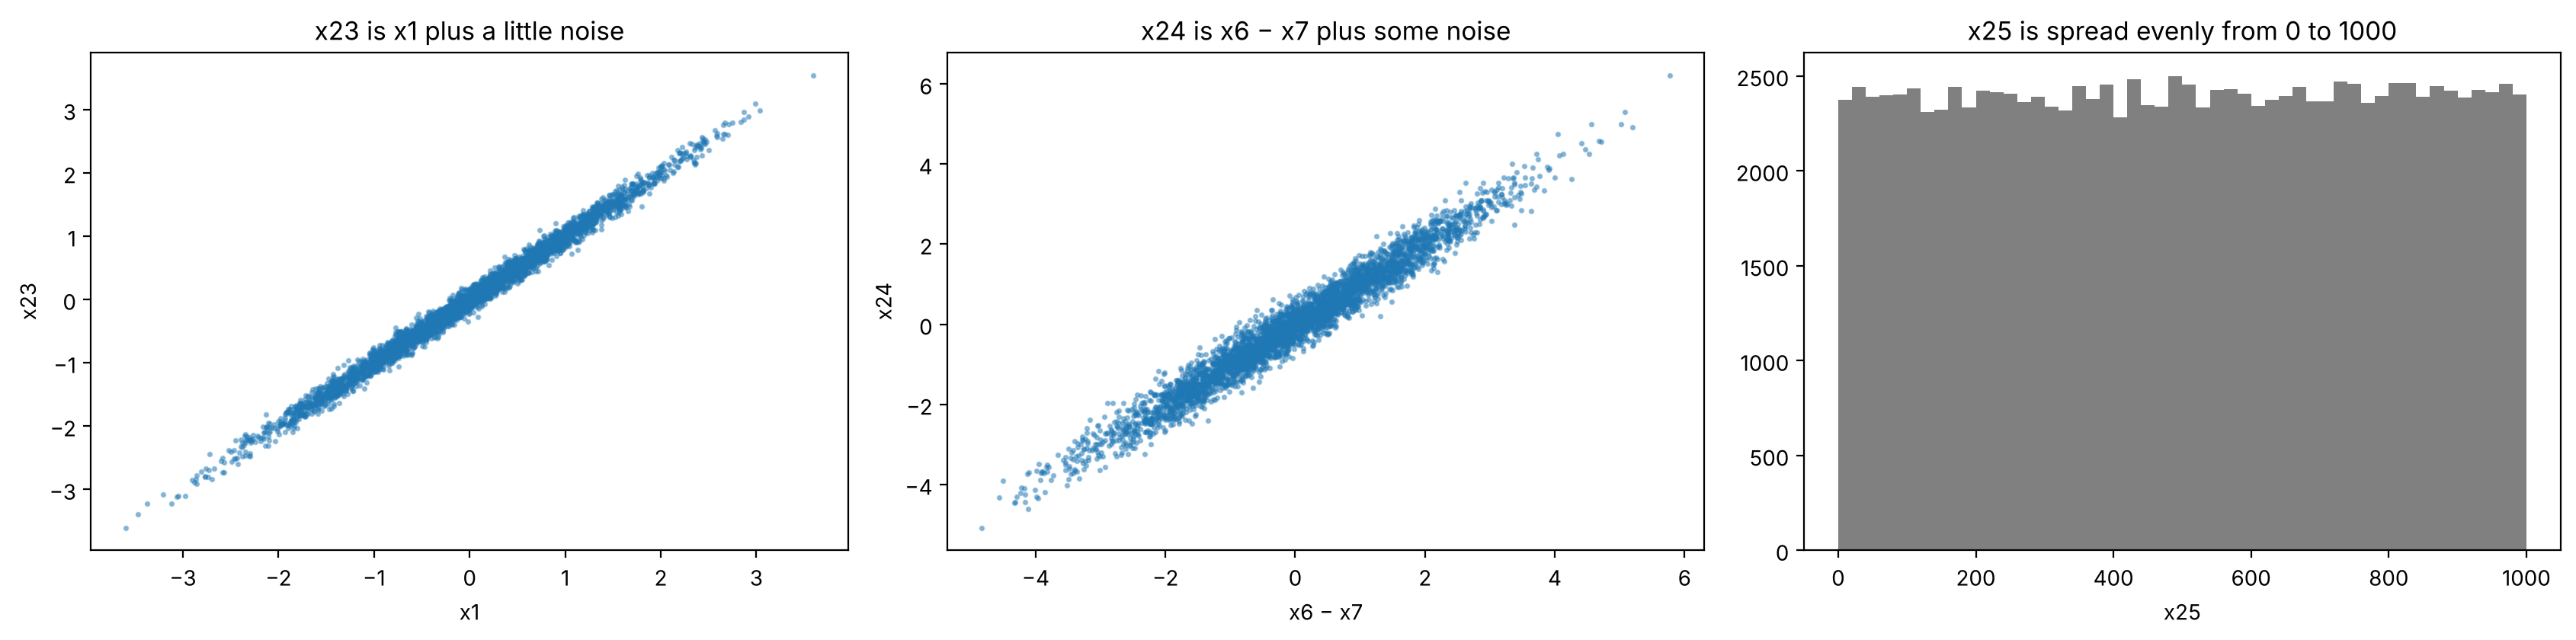

std of x23 − x1:        0.100
std of x24 − (x6 − x7): 0.301


In [8]:
sample = train.sample(4000, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].scatter(sample["x1"], sample["x23"], s=3, alpha=0.4)
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x23"); axes[0].set_title("x23 is x1 plus a little noise")
axes[1].scatter(sample["x6"] - sample["x7"], sample["x24"], s=3, alpha=0.4)
axes[1].set_xlabel("x6 − x7"); axes[1].set_ylabel("x24"); axes[1].set_title("x24 is x6 − x7 plus some noise")
axes[2].hist(train["x25"], bins=50, color="grey")
axes[2].set_xlabel("x25"); axes[2].set_title("x25 is spread evenly from 0 to 1000")
plt.tight_layout()
plt.show()

print(f"std of x23 − x1:        {(train['x23'] - train['x1']).std():.3f}")
print(f"std of x24 − (x6 − x7): {(train['x24'] - (train['x6'] - train['x7'])).std():.3f}")

**How to read the output:** x23 = x1 + noise of about **0.10**, and x24 = (x6 − x7) + noise of about **0.30**. These near-copies are a trap: a model can use the noisy copy (x24) instead of the real thing (x6 − x7) and lose accuracy. x25 is completely flat between 0 and 1000, which is unusual because every other clue is bell-shaped around 0.

### Step 2.5: Is the test row normal?

First, one clue at a time.

**What this cell does:** shows each test value as a **z-score** (how many std from the average) and the share of training rows that are further out on that clue.

In [9]:
z_test = (test[xs].iloc[0] - train[xs].mean()) / train[xs].std()
further_out = pd.Series({c: (np.abs((train[c] - train[c].mean()) / train[c].std()) > abs(z_test[c])).mean() for c in xs})
display(pd.DataFrame({"test value": test[xs].iloc[0], "z-score": z_test, "training rows further out": further_out})
        .T.round(2))
print(f"Largest |z-score| of the test row: {z_test.abs().max():.2f}")

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x16,x17,x18,x19,x20,x21,x22,x23,x24,x25
test value,0.60,0.50,1.10,-0.90,0.40,-1.29,-1.59,0.20,-0.30,1.30,...,-1.23,0.48,-0.99,0.95,0.74,-1.06,1.19,0.63,0.63,468.09
z-score,0.59,0.50,1.10,-0.90,0.40,-1.28,-1.59,0.19,-0.30,1.30,...,-1.23,0.48,-0.99,0.95,0.74,-1.05,1.19,0.62,0.41,-0.12
training rows further out,0.55,0.61,0.27,0.37,0.69,0.20,0.11,0.85,0.76,0.19,...,0.22,0.63,0.32,0.34,0.46,0.29,0.23,0.53,0.68,0.93


Largest |z-score| of the test row: 1.59


**How to read the output:** every test value is ordinary. The largest z-score is about **1.6**, so at least 11% of training rows are further out on every single clue. (x25 = 468 sits in the middle of 0–1000.)

### Step 2.6: Is the test row normal when we look at all clues together?

Think of **height and weight**: 190 cm is normal, 50 kg is normal, but a person who is 190 cm **and** 50 kg is very unusual, because height and weight normally move together. The **pattern distance** measures exactly that: how unusual a row is, given how the clues normally move together.

**What this cell does:**
1. computes the pattern distance (squared) of every training row and of the test row, using x1–x24
2. finds the **hidden directions**: combinations of clues that barely vary in the training data (the "recipes" that tie the clues together), and checks where the test row sits along them

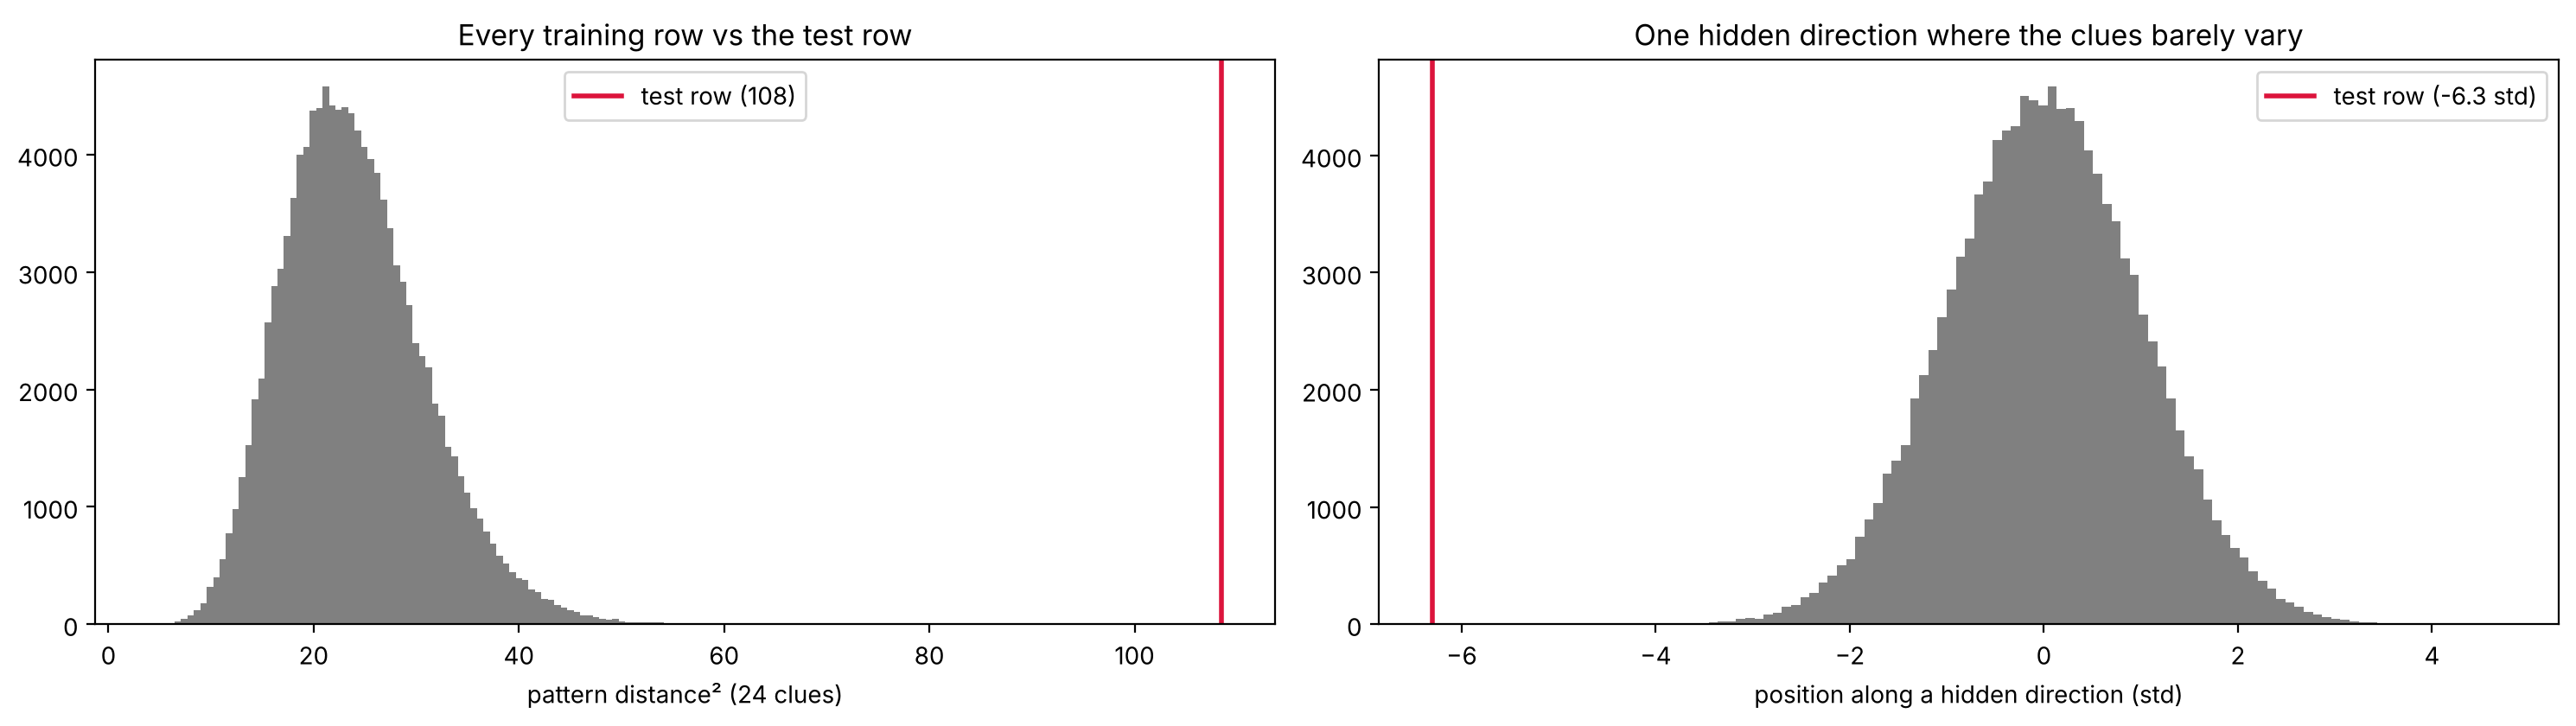

Pattern distance²: training median 23.3, 99.9th percentile 51.7, largest 66.7, TEST 108.5
Hidden direction 1: training rows between -4.9 and +4.8 std, test row +5.4 std
Hidden direction 2: training rows between -4.4 and +4.5 std, test row -0.3 std
Hidden direction 3: training rows between -4.7 and +4.8 std, test row -6.3 std


In [10]:
Z = train[xs[:24]].values
centre_point = Z.mean(axis=0)
inverse_cov = np.linalg.inv(np.cov(Z, rowvar=False))

def pattern_distance(rows):
    gap = rows - centre_point
    return np.einsum("ij,jk,ik->i", gap, inverse_cov, gap)      # squared Mahalanobis distance of each row

dist_train = pattern_distance(Z)
dist_test = pattern_distance(test[xs[:24]].values)[0]

spread_sizes, directions = np.linalg.eigh(np.cov(Z, rowvar=False))      # smallest spread first
along_train = (Z - centre_point) @ directions[:, 2]
along_test = float((test[xs[:24]].values[0] - centre_point) @ directions[:, 2]) / along_train.std()
along_train = along_train / along_train.std()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].hist(dist_train, bins=100, color="grey")
axes[0].axvline(dist_test, color="crimson", linewidth=2, label=f"test row ({dist_test:.0f})")
axes[0].set_xlabel("pattern distance² (24 clues)"); axes[0].set_title("Every training row vs the test row"); axes[0].legend()
axes[1].hist(along_train, bins=100, color="grey")
axes[1].axvline(along_test, color="crimson", linewidth=2, label=f"test row ({along_test:.1f} std)")
axes[1].set_xlabel("position along a hidden direction (std)"); axes[1].set_title("One hidden direction where the clues barely vary"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Pattern distance²: training median {np.median(dist_train):.1f}, 99.9th percentile {np.quantile(dist_train, 0.999):.1f}, "
      f"largest {dist_train.max():.1f}, TEST {dist_test:.1f}")
for k in range(3):
    a_train = (Z - centre_point) @ directions[:, k]
    a_test = float((test[xs[:24]].values[0] - centre_point) @ directions[:, k]) / a_train.std()
    print(f"Hidden direction {k + 1}: training rows between {a_train.min() / a_train.std():+.1f} and {a_train.max() / a_train.std():+.1f} std, test row {a_test:+.1f} std")

**How to read the output**

* The test row's pattern distance² is about **108**. Half the training rows are below about 23, and the most unusual of all 120,000 is about **67**. So the test row is **further from the pattern than any training row**.
* Along two of the hidden directions, the test row sits at about **+5.4** and **−6.3 std**. No training row goes past about ±5.

**What it means:** each clue is normal on its own, but the test row **breaks the recipes that tie the clues together**. A model that learned shortcuts like "when x13 is high, x3 is usually high too" will meet a combination it has never seen. A model that uses **each clue directly**, through the true formula, doesn't care. That's why finding the true formula matters so much here, and why Part 4 adds a stress test on the most unusual rows.

> **✅ Checkpoint.** Prefix and tier matter. x23 ≈ x1 and x24 ≈ x6 − x7 are near-copies. x25 looks useless (correlation 0). The test row breaks the pattern between the clues.

---
# Part 3: Find the formula

### Step 3.1: Straight line vs trees

**What this cell does:** compares a straight-line model (all clues plus the groups) with a tree model (HistGB), using 3-fold cross-validation. If the trees are much better, the price has curves or team effects that the straight line can't see.

In [11]:
cols = xs + ["prefix", "mode", "tier"]
X, y, X_test = train[cols], train["price"], test[cols]
cv3 = KFold(n_splits=3, shuffle=True, random_state=0)

def encoder(scale=True):
    # numbers are (optionally) scaled, prefix and mode become 0/1 columns
    numbers = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([("numbers", numbers, xs + ["tier"]),
                              ("groups", OneHotEncoder(drop="first", handle_unknown="ignore"), ["prefix", "mode"])])

line = Pipeline([("prep", encoder()), ("model", LinearRegression())])
trees = Pipeline([("prep", encoder(False)), ("model", HistGradientBoostingRegressor(max_iter=300, random_state=0))])
for name, model in [("Straight line", line), ("Trees (HistGB)", trees)]:
    score = -cross_val_score(model, X, y, cv=cv3, scoring="neg_root_mean_squared_error").mean()
    print(f"{name:15s} CV RMSE £{score:.2f}")
print(f"Price std (the error if we always guessed the average): £{y.std():.2f}")

Straight line   CV RMSE £25.88


Trees (HistGB)  CV RMSE £11.34
Price std (the error if we always guessed the average): £34.84


**How to read the output:** the straight line is wrong by about **£26**, the trees by about **£11**. The trees are more than twice as good, so the price has a lot of **hidden shape**. The trees don't tell us **what** the shape is, so we go looking.

### Step 3.2: One curve per clue

A `SplineTransformer` lets a linear model draw a **smooth curve** for each clue instead of a straight line. Each curve shows how that clue moves the price when the others stay fixed.

**What this cell does:** fits one curve per clue (plus the groups) and draws all 25 curves. The red dashed line is the test row's value.

One curve per clue: leftover std £20.97


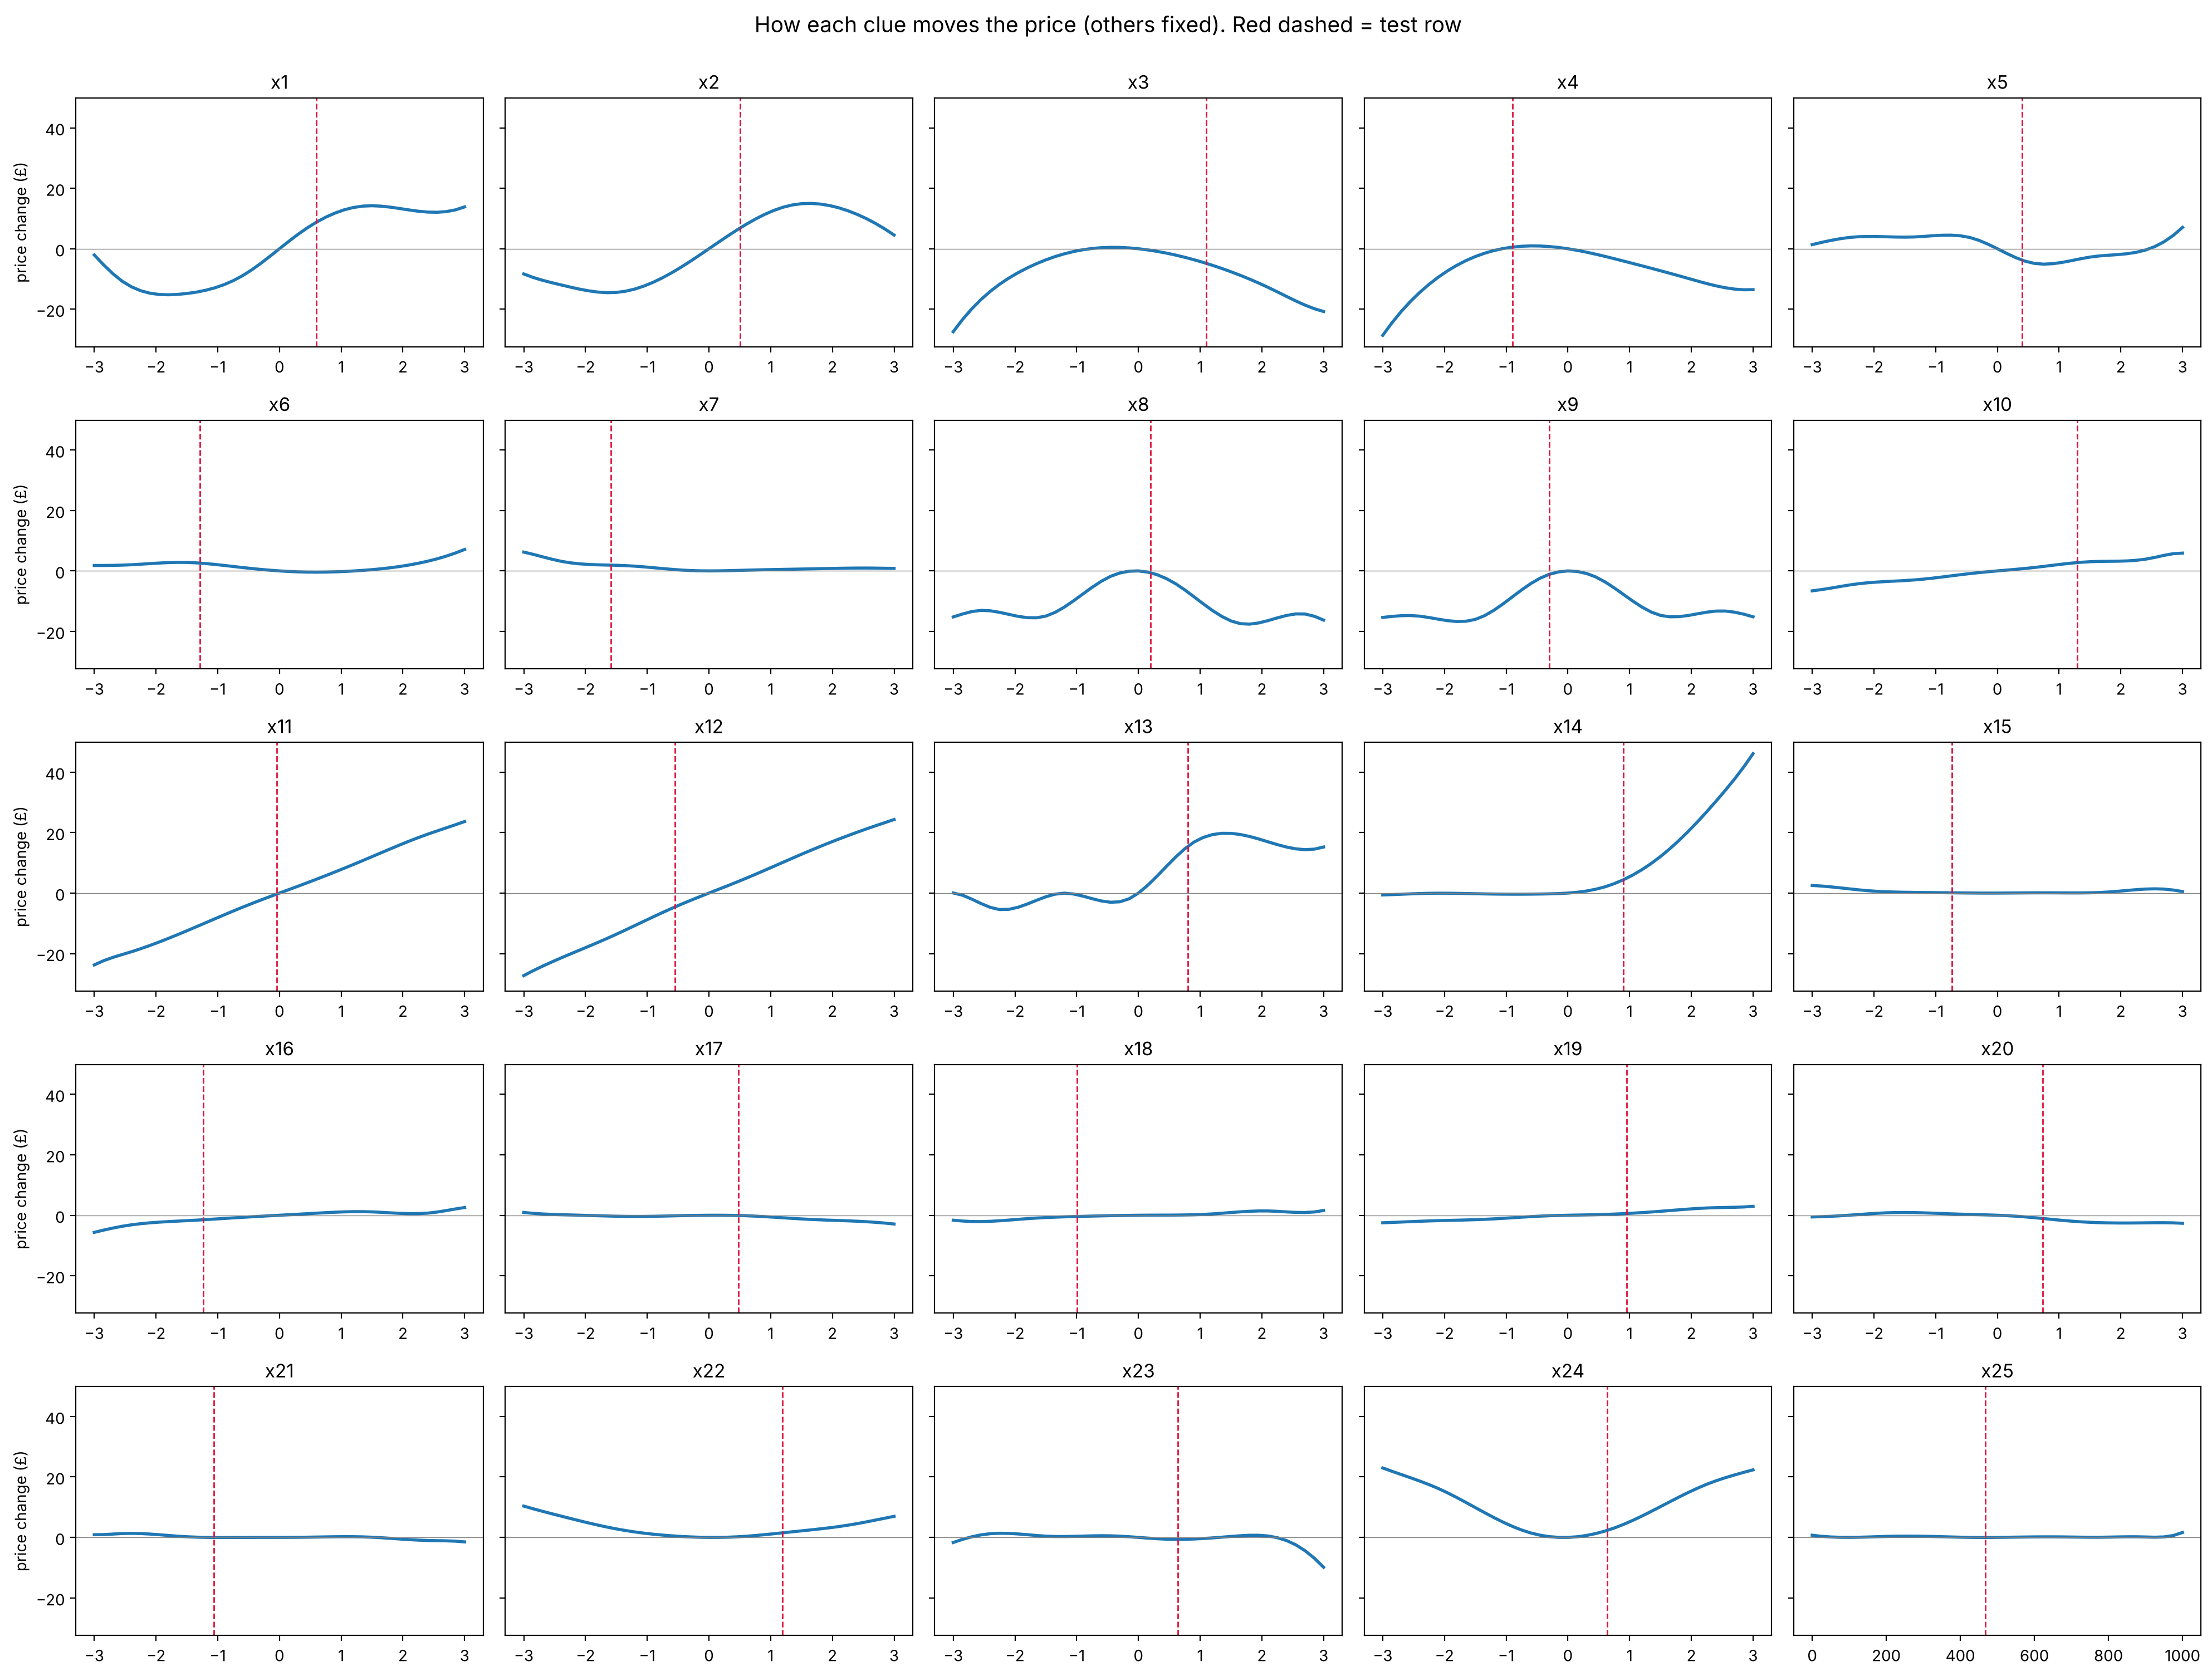

In [12]:
curves = Pipeline([("prep", ColumnTransformer([("curves", SplineTransformer(n_knots=10, degree=3), xs),
                                               ("groups", OneHotEncoder(drop="first"), ["prefix", "mode", "tier"])])),
                   ("model", Ridge(alpha=0.1))]).fit(X, y)
print(f"One curve per clue: leftover std £{(y - curves.predict(X)).std():.2f}")

base_row = X.iloc[[0]].copy()               # a made-up row: every clue at 0 (x25 at 500), prefix WXM, mode B, tier 3
base_row[xs] = 0.0
base_row["x25"] = 500.0
base_row["prefix"], base_row["mode"], base_row["tier"] = "WXM", "B", 3
start = curves.predict(base_row)[0]

fig, axes = plt.subplots(5, 5, figsize=(20, 15), sharey=True)
for ax, clue in zip(axes.ravel(), xs):
    grid = np.linspace(0, 1000, 41) if clue == "x25" else np.linspace(-3, 3, 41)
    rows = pd.concat([base_row] * len(grid), ignore_index=True)
    rows[clue] = grid
    ax.plot(grid, curves.predict(rows) - start, linewidth=2)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(test[clue].item(), color="crimson", linestyle="--", linewidth=1)
    ax.set_title(clue)
for ax in axes[:, 0]:
    ax.set_ylabel("price change (£)")
fig.suptitle("How each clue moves the price (others fixed). Red dashed = test row", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

**How to read the output:** the leftover drops from about £26 to about **£21**. Each curve gives a hint:

| Clue | Shape | First guess |
|---|---|---|
| x11, x12 | straight, about +8 per unit | simple line |
| x10 | small slope only | strange, see Step 3.3 |
| x13 | **jumps by about £20** between 0 and 1 | a switch |
| x14 | flat below 0, then curves up fast | a **hinge**: only counts above 0 |
| x1, x2 | rise to about +15, then fall back | a wave, like sin |
| x3, x4 | fall away on both sides | a hump, like −x² (or a team effect) |
| x8, x9 | dip of about −15 away from 0 | a bump around 0 |
| x24 | V or U shape | something like \|x24\| or x24² |
| x5 | drops at 0 | maybe a switch (Step 3.6 explains it) |
| x15–x23, x25 | about flat (x22 and x23 bend a little at the edges) | maybe useless |

But one curve per clue can't show team effects, and the leftover is still £21 against the trees' £12. So something is still missing.

### Step 3.3: Does `mode` change how a clue works?

Mode barely moved the average price (Step 2.1). But a group can **change the slope** of a clue without moving the average.

**What this cell does:** fits the same curves, but gives `x10` a **separate straight line in each mode**. It then plots, for each mode, the price explained by x10 (leftover + x10's part) in 20 slices of x10.

Curves + x10 per mode: leftover std £18.12
x10 slope in each mode: {'A': np.float64(11.96), 'B': np.float64(-11.78), 'C': np.float64(3.51)}


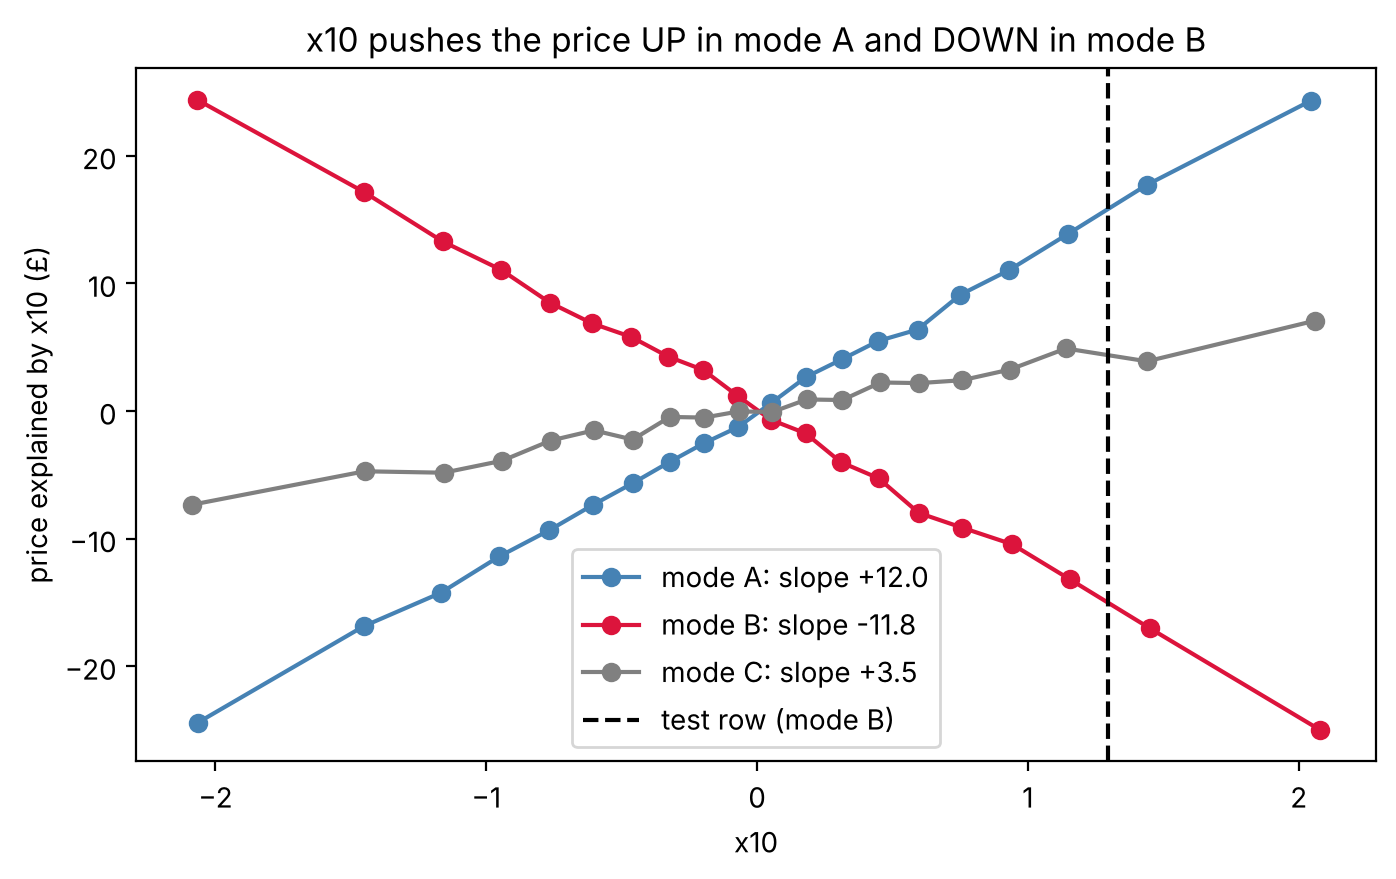

In [13]:
def x10_by_mode(d):
    # x10 copied into three columns, one per mode (0 in the other modes)
    return pd.DataFrame({f"x10_mode{m}": d["x10"] * (d["mode"] == m) for m in "ABC"}, index=d.index)

curves_mode = Pipeline([("prep", ColumnTransformer([
        ("curves", SplineTransformer(n_knots=10, degree=3), [c for c in xs if c != "x10"]),
        ("x10", FunctionTransformer(x10_by_mode, feature_names_out=lambda self, names: ["x10_modeA", "x10_modeB", "x10_modeC"]), ["x10", "mode"]),
        ("groups", OneHotEncoder(drop="first"), ["prefix", "mode", "tier"])])),
    ("model", Ridge(alpha=0.1))]).fit(X, y)
leftover_curves = y - curves_mode.predict(X)
weights = pd.Series(curves_mode["model"].coef_, curves_mode[:-1].get_feature_names_out())
x10_slopes = {m: weights[f"x10__x10_mode{m}"] for m in "ABC"}
print(f"Curves + x10 per mode: leftover std £{leftover_curves.std():.2f}")
print("x10 slope in each mode:", {m: round(v, 2) for m, v in x10_slopes.items()})

plt.figure(figsize=(8, 4.5))
for m, colour in zip("ABC", ["steelblue", "crimson", "grey"]):
    in_mode = train["mode"] == m
    explained = leftover_curves[in_mode] + x10_slopes[m] * train.loc[in_mode, "x10"]
    slices = pd.qcut(train.loc[in_mode, "x10"], 20)
    plt.plot(train.loc[in_mode, "x10"].groupby(slices, observed=True).mean(), explained.groupby(slices, observed=True).mean(),
             marker="o", color=colour, label=f"mode {m}: slope {x10_slopes[m]:+.1f}")
plt.axvline(test["x10"].item(), color="black", linestyle="--", label="test row (mode B)")
plt.xlabel("x10"); plt.ylabel("price explained by x10 (£)")
plt.title("x10 pushes the price UP in mode A and DOWN in mode B")
plt.legend()
plt.show()

**How to read the output**

* In **mode A**, each unit of x10 adds about **+£12**. In **mode B** it takes away about **£12**. In **mode C** it adds about **£3.5**.
* Mixed together, these cancel out, which is why x10's overall correlation is weak and its curve in Step 3.2 was small.
* The leftover drops from about £21 to about **£18**.

**The test row is mode B with x10 = +1.30**, so x10 **lowers** its price by about **£15.5**. A model that misses the flip would push it the other way.

### Step 3.4: Search for team effects

Now we look at the leftover for **pairs** of clues. If two clues work as a team, the leftover will show a pattern in a grid of the two, even when each clue alone looks fine.

**What this cell does:** cuts each clue of a pair into 8 slices and colours the average leftover in each of the 8 × 8 cells. Red = the model is too low there, blue = too high.

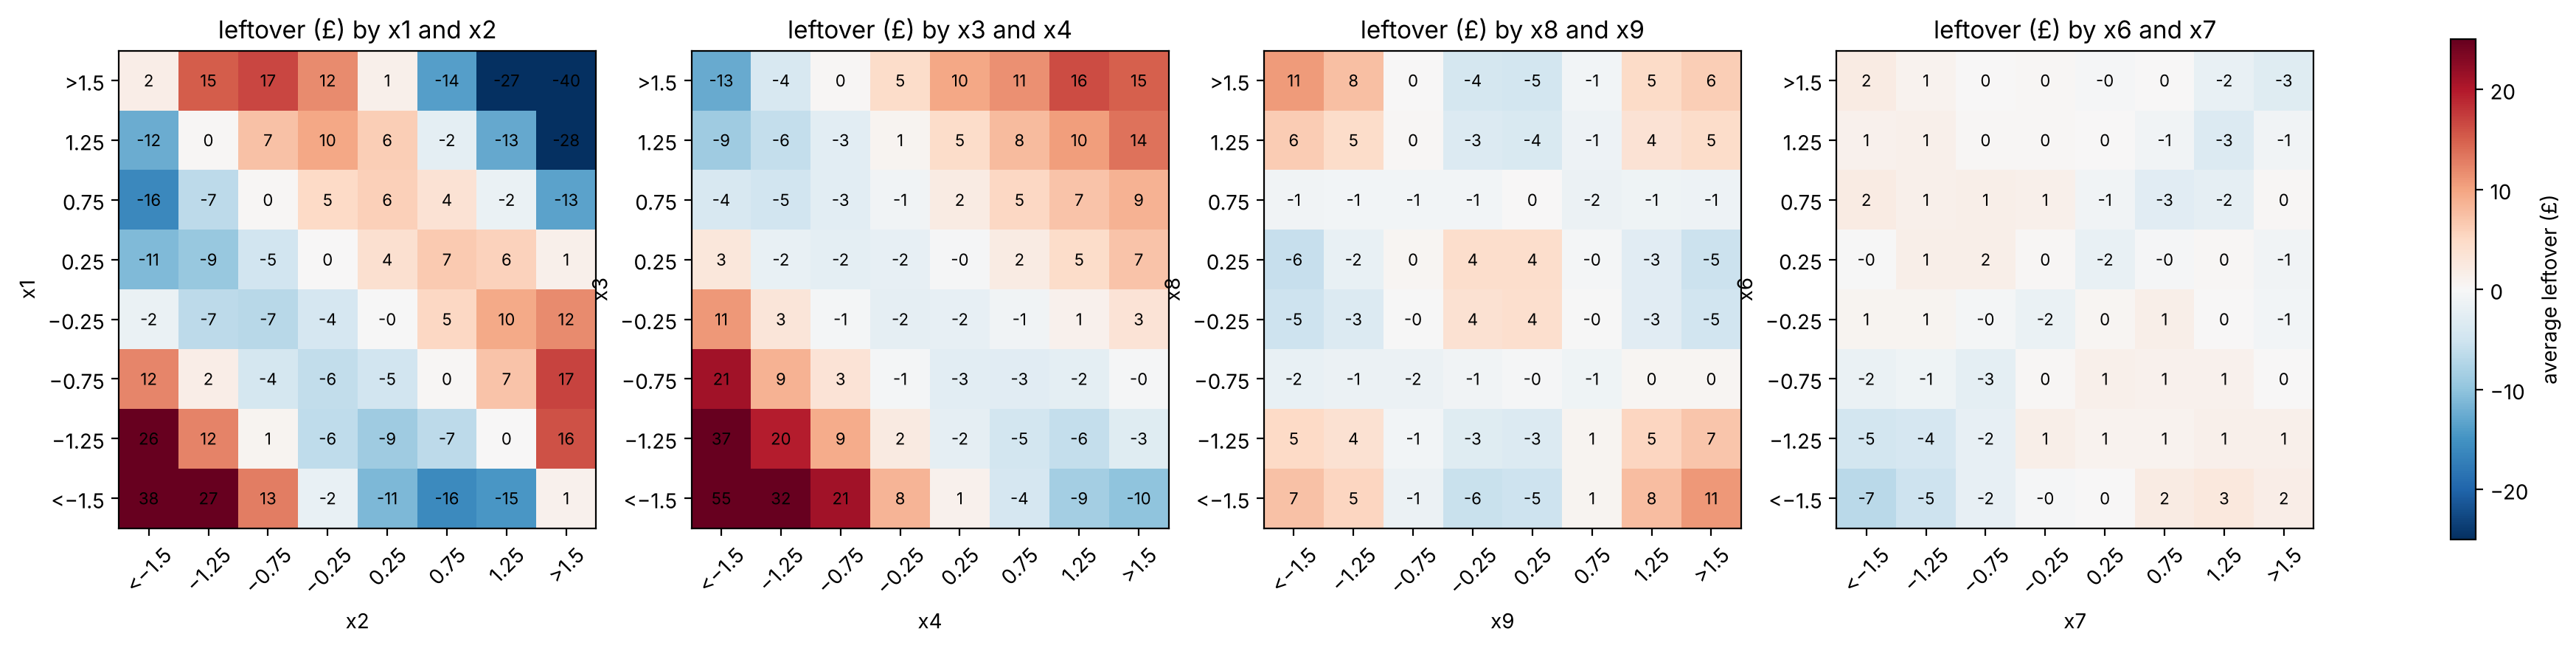

In [14]:
edges = [-np.inf, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, np.inf]
labels = ["<−1.5", "−1.25", "−0.75", "−0.25", "0.25", "0.75", "1.25", ">1.5"]

fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for ax, (a, b) in zip(axes, [("x1", "x2"), ("x3", "x4"), ("x8", "x9"), ("x6", "x7")]):
    grid = leftover_curves.groupby([pd.cut(train[a], edges), pd.cut(train[b], edges)], observed=True).mean().unstack()
    image = ax.imshow(grid.values, cmap="RdBu_r", vmin=-25, vmax=25, origin="lower")
    for i in range(8):
        for j in range(8):
            ax.text(j, i, f"{grid.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(8)); ax.set_xticklabels(labels, rotation=45)
    ax.set_yticks(range(8)); ax.set_yticklabels(labels)
    ax.set_xlabel(b); ax.set_ylabel(a)
    ax.set_title(f"leftover (£) by {a} and {b}")
fig.colorbar(image, ax=axes, shrink=0.8, label="average leftover (£)")
plt.show()

**How to read the output**

| Pair | Pattern | What it means |
|---|---|---|
| **x1, x2** | **diagonal stripes** running from top-left to bottom-right | the leftover depends on **x1 + x2**, so the wave is **sin(x1 + x2)**, not a separate wave for each clue |
| **x3, x4** | positive when the signs **match** (both low or both high), negative when they **differ** | a team effect **x3 × x4** |
| **x8, x9** | a **chessboard**: the centre and the corners are red, the edges in between are blue | **one bump** around (0, 0) for both together, not two separate bumps |
| **x6, x7** | a weaker pattern: mostly blue along the **diagonal** (x6 ≈ x7), slightly red away from it | the price depends on the **gap \|x6 − x7\|** (x24 was only a noisy copy of x6 − x7) |

### Step 3.5: Test the team ideas

To compare ideas fairly, we build a table of **ingredients** and fit a straight-line model on a chosen set of them. Each ingredient is just a column (e.g. `sin(x1+x2)`), so the model only has to find one weight per column.

**What this cell does:**
1. builds the ingredient table
2. sets a **base** of simple pieces: the groups, every clue as a straight line, x10 per mode, an x13 switch at 0.5 and an x14 hinge (x14² above 0)
3. adds the four team ideas, then swaps each one for the **separate** version, to see which fits better

In [15]:
def pieces(d):
    p = pd.DataFrame(index=d.index)
    for q in prefixes[1:]:
        p[f"prefix_{q}"] = (d["prefix"] == q).astype(float)        # one 0/1 column per prefix (BHX is the baseline)
    p["mode_B"] = (d["mode"] == "B").astype(float)
    p["mode_C"] = (d["mode"] == "C").astype(float)
    p["tier"] = d["tier"]
    for c in xs:
        p[c] = d[c]                                                 # every clue as a straight line
    for m in "ABC":
        p[f"x10_mode{m}"] = d["x10"] * (d["mode"] == m)             # x10 with its own slope in each mode
    p["x13_step"] = (d["x13"] > 0.5).astype(float)                  # 1 when x13 is above 0.5
    p["x14_hinge2"] = np.maximum(d["x14"], 0) ** 2                  # 0 below 0, then x14²
    p["sin(x1)"], p["sin(x2)"] = np.sin(d["x1"]), np.sin(d["x2"])
    p["sin(x1+x2)"] = np.sin(d["x1"] + d["x2"])
    p["x3^2"], p["x4^2"] = d["x3"] ** 2, d["x4"] ** 2
    p["x3*x4"] = d["x3"] * d["x4"]
    p["bump(x8)"], p["bump(x9)"] = np.exp(-d["x8"] ** 2), np.exp(-d["x9"] ** 2)
    p["bump(x8,x9)"] = np.exp(-(d["x8"] ** 2 + d["x9"] ** 2))      # one bump for both: 1 at (0, 0), fading to 0
    p["x24^2"], p["|x24|"] = d["x24"] ** 2, d["x24"].abs()
    p["|x6-x7|"] = (d["x6"] - d["x7"]).abs()
    return p

P_train, P_test = pieces(train), pieces(test)

def fit_pieces(names):
    model = LinearRegression().fit(P_train[names], y)
    return model, y - model.predict(P_train[names])

base = [c for c in P_train.columns if c.startswith("prefix_")] + ["mode_B", "mode_C", "tier"] \
       + [c for c in xs if c != "x10"] + ["x10_modeA", "x10_modeB", "x10_modeC", "x13_step", "x14_hinge2"]
teams = ["sin(x1+x2)", "x3*x4", "bump(x8,x9)", "|x6-x7|"]
scoreboard = {"Straight lines only": fit_pieces([c for c in P_train.columns if c.startswith("prefix_")] + ["mode_B", "mode_C", "tier"] + xs)[1].std(),
              "+ x10 per mode, x13 switch, x14 hinge": fit_pieces(base)[1].std(),
              "+ 4 team effects": fit_pieces(base + teams)[1].std()}

swaps = [("x1, x2", "sin(x1+x2)", ["sin(x1)", "sin(x2)"]),
         ("x3, x4", "x3*x4", ["x3^2", "x4^2"]),
         ("x8, x9", "bump(x8,x9)", ["bump(x8)", "bump(x9)"]),
         ("x6, x7", "|x6-x7|", ["x24^2"]),
         ("x6, x7", "|x6-x7|", ["|x24|"])]
rows = []
for pair, team, separate in swaps:
    others = [t for t in teams if t != team]
    rows.append({"pair": pair, "separate version": " + ".join(separate),
                 "RMSE separate (£)": round(fit_pieces(base + others + separate)[1].std(), 2),
                 "team version": team, "RMSE team (£)": round(scoreboard["+ 4 team effects"], 2)})
print(f"Base only: £{scoreboard['+ x10 per mode, x13 switch, x14 hinge']:.2f}    Base + 4 team effects: £{scoreboard['+ 4 team effects']:.2f}")
pd.DataFrame(rows)

Base only: £22.81    Base + 4 team effects: £13.24


,pair,separate version,RMSE separate (£),team version,RMSE team (£)
0,"x1, x2",sin(x1) + sin(x2),16.53,sin(x1+x2),13.24
1,"x3, x4",x3^2 + x4^2,14.61,x3*x4,13.24
2,"x8, x9",bump(x8) + bump(x9),13.69,"bump(x8,x9)",13.24
3,"x6, x7",x24^2,13.83,|x6-x7|,13.24
4,"x6, x7",|x24|,13.56,|x6-x7|,13.24


**How to read the output:** the base is wrong by about **£23**. With the four team ideas the leftover falls to about **£13**. And in **every** row of the table, the team version beats the separate version:

* sin(x1 + x2) beats sin(x1) + sin(x2) by about £3
* x3 × x4 beats two humps (x3², x4²) by about £1.4
* one joint bump beats two separate bumps by about £0.5
* |x6 − x7| beats both x24² and |x24| by about £0.3–0.6. The **real** gap beats its noisy copy.

### Step 3.6: x3 × x4 only works when x5 > 0

The x5 curve in Step 3.2 dropped at 0. Maybe x5 is a **switch** for the x3 × x4 team.

**What this cell does:** fits everything except x3 × x4, then, in 8 slices of x5, measures how strongly the leftover follows x3 × x4 (the slope).

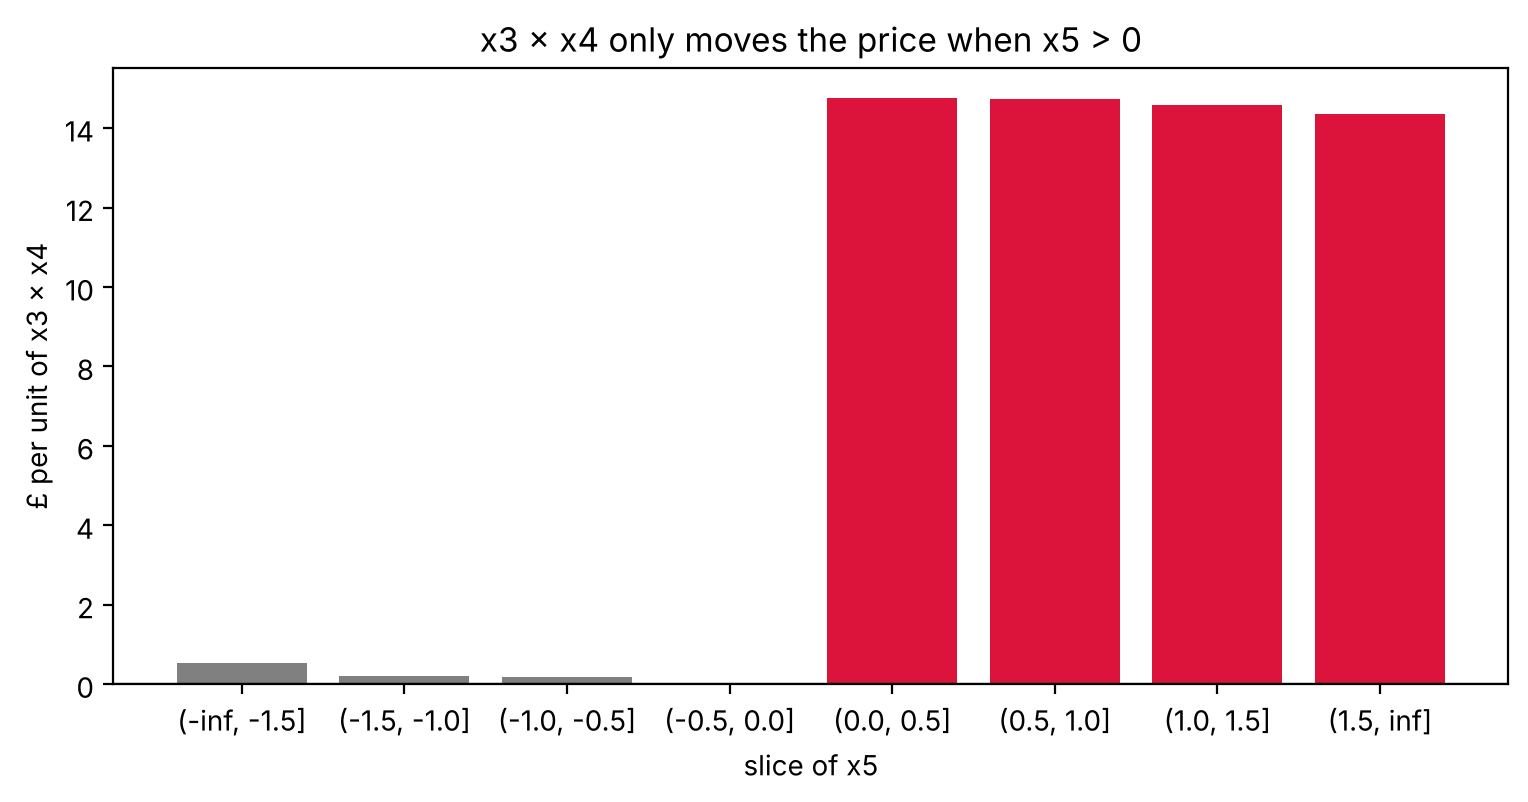

(-inf, -1.5]     0.52
(-1.5, -1.0]     0.20
(-1.0, -0.5]     0.18
(-0.5, 0.0]      0.02
(0.0, 0.5]      14.77
(0.5, 1.0]      14.73
(1.0, 1.5]      14.57
(1.5, inf]      14.35



Leftover std with the switch: £10.46


In [16]:
_, leftover = fit_pieces(base + [t for t in teams if t != "x3*x4"])
x3x4 = train["x3"] * train["x4"]
x5_slices = pd.cut(train["x5"], [-np.inf, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, np.inf])
x3x4_slope = pd.Series({str(s): np.polyfit(x3x4[x5_slices == s], leftover[x5_slices == s], 1)[0] for s in x5_slices.cat.categories})

plt.figure(figsize=(9, 4))
plt.bar(x3x4_slope.index, x3x4_slope.values, color=["grey"] * 4 + ["crimson"] * 4)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("slice of x5"); plt.ylabel("£ per unit of x3 × x4")
plt.title("x3 × x4 only moves the price when x5 > 0")
plt.show()
print(x3x4_slope.round(2).to_string())

for P, d in [(P_train, train), (P_test, test)]:
    P["x3*x4 if x5>0"] = d["x3"] * d["x4"] * (d["x5"] > 0)
teams = ["sin(x1+x2)", "x3*x4 if x5>0", "bump(x8,x9)", "|x6-x7|"]
scoreboard["x3 × x4 only when x5 > 0"] = fit_pieces(base + teams)[1].std()
print(f"\nLeftover std with the switch: £{scoreboard['x3 × x4 only when x5 > 0']:.2f}")

**How to read the output:** when x5 is **below 0**, x3 × x4 does nothing (slope about 0). When x5 is **above 0**, every unit of x3 × x4 adds about **£14.5**, in every slice. So x5 is an **on/off switch**: x5 itself doesn't move the price, it decides whether the x3 × x4 team counts. With the switch, the leftover drops from about £13 to about **£10.5**.

**The test row has x5 = +0.40** (switch on) and x3 × x4 = 1.10 × (−0.90) = −0.99, so this team takes about **£15** off its price.

### Step 3.7: Does the x13 jump depend on the tier?

**What this cell does:** gives the x13 switch a **separate size in each tier** and plots the five sizes.

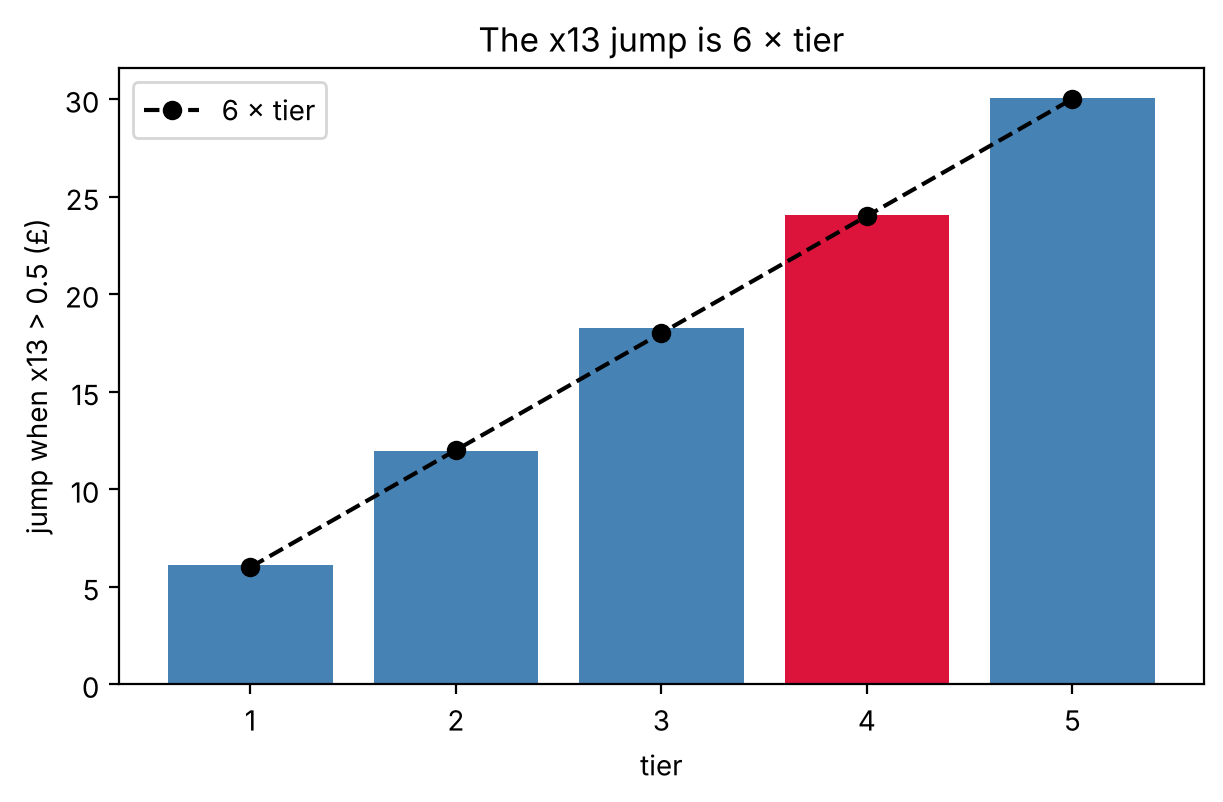

Jump per tier (£): [ 6.12 11.94 18.25 24.03 30.07]


Leftover std: £9.70


In [17]:
for P, d in [(P_train, train), (P_test, test)]:
    for t in range(1, 6):
        P[f"x13_step_tier{t}"] = P["x13_step"] * (d["tier"] == t)
    P["tier*x13_step"] = d["tier"] * P["x13_step"]

per_tier = [f"x13_step_tier{t}" for t in range(1, 6)]
model, _ = fit_pieces([n for n in base if n != "x13_step"] + per_tier + teams)
jump = pd.Series(model.coef_, [n for n in base if n != "x13_step"] + per_tier + teams)[per_tier].values

plt.figure(figsize=(7, 4))
plt.bar(range(1, 6), jump, color=["crimson" if t == 4 else "steelblue" for t in range(1, 6)])
plt.plot(range(1, 6), 6 * np.arange(1, 6), "k--", marker="o", label="6 × tier")
plt.xlabel("tier"); plt.ylabel("jump when x13 > 0.5 (£)")
plt.title("The x13 jump is 6 × tier")
plt.legend()
plt.show()
print("Jump per tier (£):", jump.round(2))

base = [n for n in base if n != "tier"] + ["tier*x13_step"]
scoreboard["x13 jump = 6 × tier"] = fit_pieces(base + teams)[1].std()
print(f"Leftover std: £{scoreboard['x13 jump = 6 × tier']:.2f}")

**How to read the output:** the jumps are about **£6, 12, 18, 24 and 30** for tiers 1–5, exactly **6 × tier**. This also explains why the average price rose with the tier in Step 2.1: higher tiers get a bigger jump. Once the jump is tied to the tier, the plain tier column isn't needed any more. The leftover drops to about **£9.7**.

**The test row is tier 4 with x13 = 0.80** (above 0.5), so it gets the jump: **+£24**.

### Step 3.8: Is x25 really useless?

x25 has a correlation of **0.00** with the price, and its curve in Step 3.2 was flat. But both checks only look at slow, smooth changes. A **fast wave** that goes up and down every few units would average out to 0 in every slice.

**What this cell does:**
1. shows the leftover in 20 slices of x25 (each slice is 50 units wide)
2. runs a **wave scan**: for thousands of possible wave lengths (periods), fits a sine wave of x25 to the leftover and records how big it is
3. plots the leftover against the position inside one wave

Correlation of x25 with the leftover: 0.000


Biggest wave: period 6.402, size about £12.0


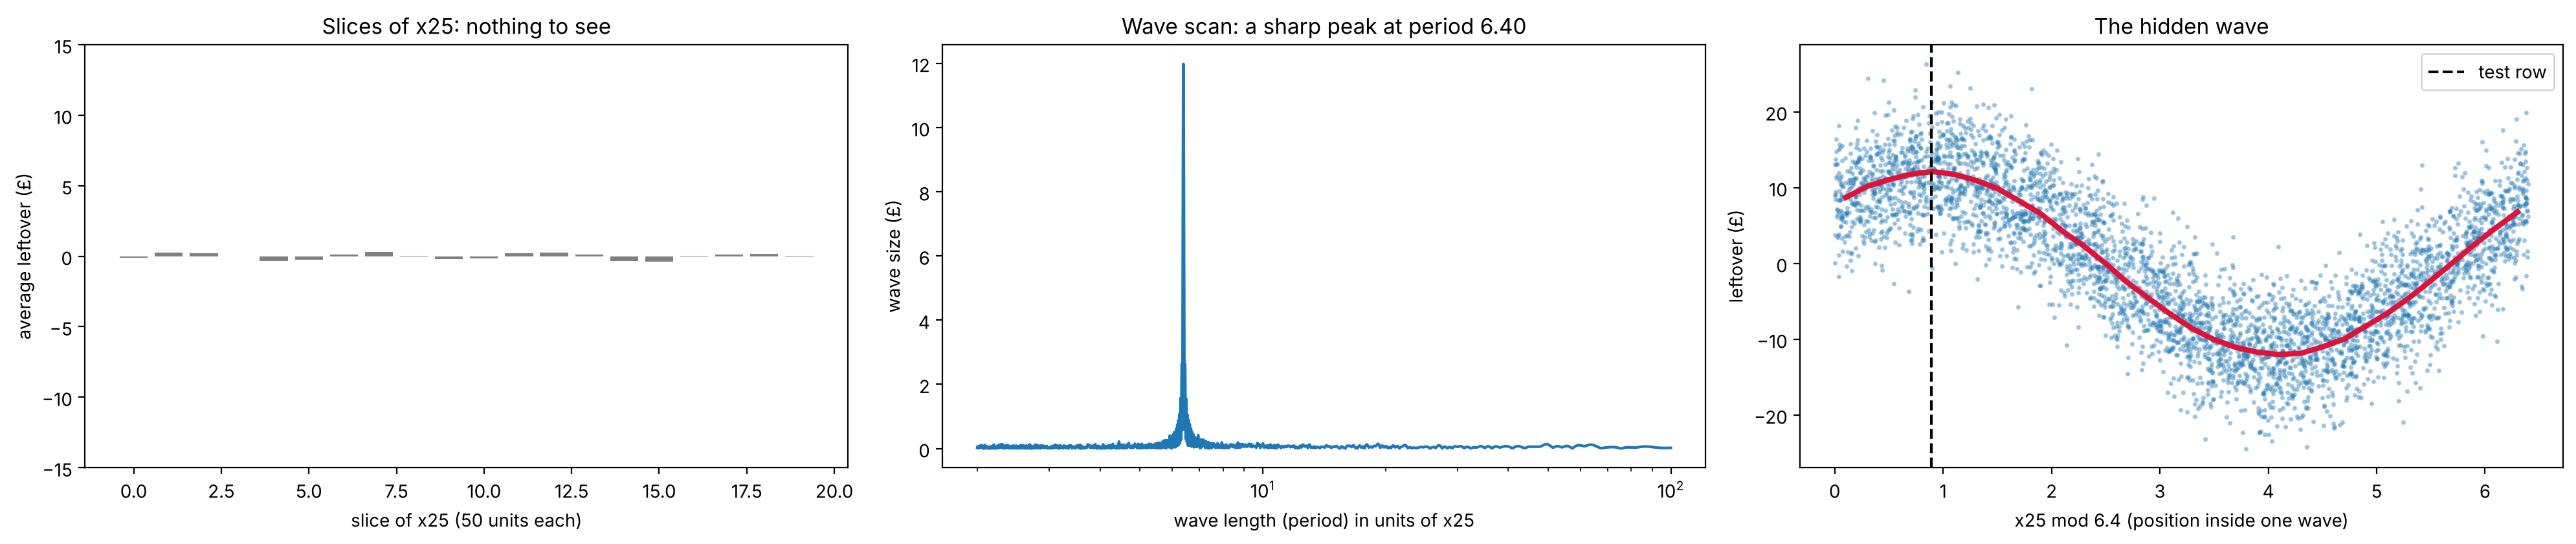

In [18]:
_, leftover = fit_pieces(base + teams)
x25 = train["x25"].values
print(f"Correlation of x25 with the leftover: {np.corrcoef(x25, leftover)[0, 1]:.3f}")

frequencies = np.arange(0.01, 0.5, 0.0001)       # waves per unit of x25 (period = 1 / frequency)
size = []
for chunk in np.array_split(frequencies, 50):
    angle = 2 * np.pi * np.outer(chunk, x25)
    a, b = np.sin(angle) @ leftover.values, np.cos(angle) @ leftover.values
    size.extend(2 * np.hypot(a, b) / len(x25))   # size (amplitude) of the best-fitting wave at each frequency
size = np.array(size)
best_period = 1 / frequencies[size.argmax()]
print(f"Biggest wave: period {best_period:.3f}, size about £{size.max():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 4.3))
slices = pd.cut(train["x25"], np.linspace(0, 1000, 21))
axes[0].bar(range(20), leftover.groupby(slices, observed=True).mean().values, color="grey")
axes[0].set_ylim(-15, 15); axes[0].set_xlabel("slice of x25 (50 units each)"); axes[0].set_ylabel("average leftover (£)")
axes[0].set_title("Slices of x25: nothing to see")
axes[1].plot(1 / frequencies, size)
axes[1].set_xscale("log"); axes[1].set_xlabel("wave length (period) in units of x25"); axes[1].set_ylabel("wave size (£)")
axes[1].set_title(f"Wave scan: a sharp peak at period {best_period:.2f}")
position = train["x25"] % 6.4
show = np.random.default_rng(0).choice(len(train), 4000, replace=False)
axes[2].scatter(position.iloc[show], leftover.iloc[show], s=3, alpha=0.3)
wave_slices = pd.cut(position, 32)
axes[2].plot(position.groupby(wave_slices, observed=True).mean(), leftover.groupby(wave_slices, observed=True).mean(), color="crimson", linewidth=3)
axes[2].axvline(test["x25"].item() % 6.4, color="black", linestyle="--", label="test row")
axes[2].set_xlabel("x25 mod 6.4 (position inside one wave)"); axes[2].set_ylabel("leftover (£)")
axes[2].set_title("The hidden wave"); axes[2].legend()
plt.tight_layout()
plt.show()

**How to read the output**

* Left: in 50-unit slices the leftover is about 0 everywhere, so x25 **looks** useless.
* Middle: the wave scan has one **sharp peak at a period of 6.4**. Every 6.4 units of x25, the price goes up and down by about **£12**. With x25 running from 0 to 1000, that's about 156 full waves, so every 50-unit slice contains about 8 waves that cancel out.
* Right: folding x25 into one wave (x25 mod 6.4, the remainder after dividing by 6.4) shows a clean sine curve.

**The test row (x25 = 468.09) sits almost exactly at the top of a wave**, so this ingredient adds about **+£12**. Teams that drop x25 because its correlation is 0 will price the test row about £12 too low.

**What this cell does:** adds the wave as two ingredients, sin and cos of 2π·x25 / 6.4. With both, the model can find the wave's size **and** where it starts.

In [19]:
for P, d in [(P_train, train), (P_test, test)]:
    P["wave_sin"] = np.sin(2 * np.pi * d["x25"] / 6.4)
    P["wave_cos"] = np.cos(2 * np.pi * d["x25"] / 6.4)
teams = teams + ["wave_sin", "wave_cos"]
scoreboard["+ x25 wave"] = fit_pieces(base + teams)[1].std()
print(f"Leftover std with the wave: £{scoreboard['+ x25 wave']:.2f}")

Leftover std with the wave: £4.66


**How to read the output:** the leftover **halves**, from about £9.7 to about **£4.7**. This "useless" clue was the biggest single improvement in Part 3.

### Step 3.9: Does x12 move smoothly, or in steps?

**What this cell does:** takes the leftover, adds back x12's straight-line part, and plots it in thin slices (0.05 wide) of x12.

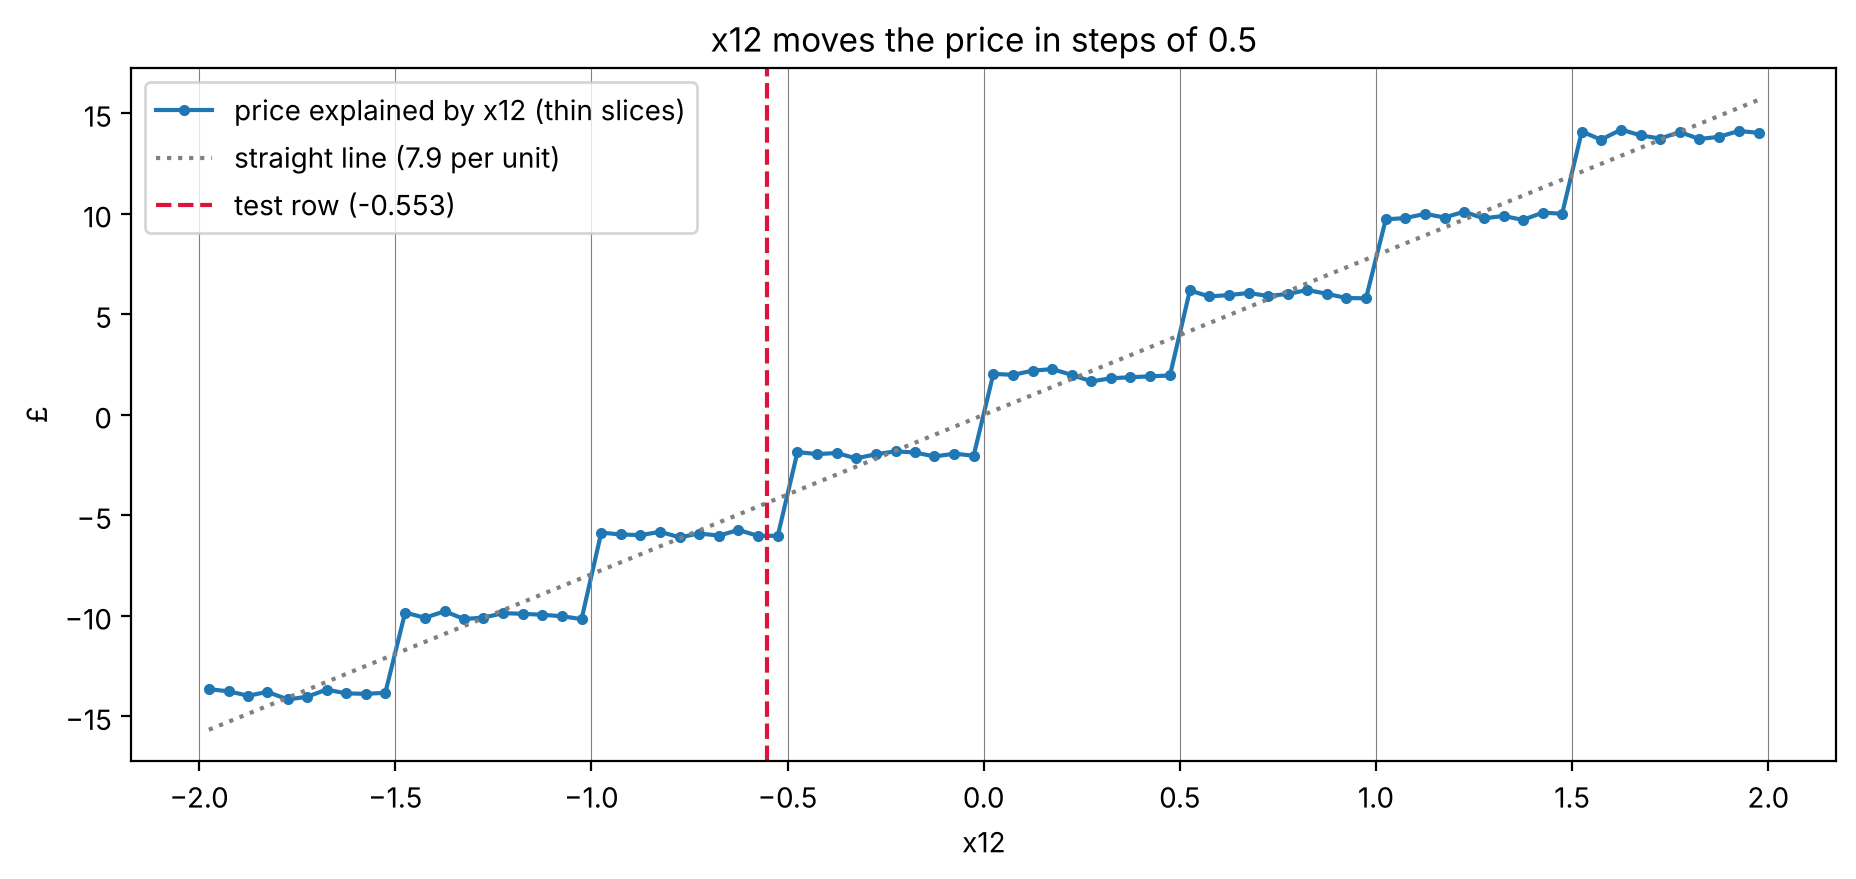

Leftover std with the staircase: £4.51


In [20]:
model, leftover = fit_pieces(base + teams)
x12_weight = pd.Series(model.coef_, base + teams)["x12"]
explained = leftover + x12_weight * train["x12"]
thin = pd.cut(train["x12"], np.arange(-2, 2.001, 0.05))
middles = train["x12"].groupby(thin, observed=True).mean()

plt.figure(figsize=(11, 4.5))
plt.plot(middles, explained.groupby(thin, observed=True).mean(), marker="o", markersize=3, label="price explained by x12 (thin slices)")
plt.plot(middles, x12_weight * middles, color="grey", linestyle=":", label=f"straight line ({x12_weight:.1f} per unit)")
plt.axvline(test["x12"].item(), color="crimson", linestyle="--", label=f"test row ({test['x12'].item():.3f})")
for edge in np.arange(-2, 2.01, 0.5):
    plt.axvline(edge, color="grey", linewidth=0.4)
plt.xlabel("x12"); plt.ylabel("£")
plt.title("x12 moves the price in steps of 0.5")
plt.legend()
plt.show()

for P, d in [(P_train, train), (P_test, test)]:
    P["x12_stair"] = (np.floor(2 * d["x12"]) + 0.5) / 2      # the middle of x12's half-unit step: ..., −0.75, −0.25, 0.25, 0.75, ...
base = [n for n in base if n != "x12"] + ["x12_stair"]
scoreboard["x12 as a staircase"] = fit_pieces(base + teams)[1].std()
print(f"Leftover std with the staircase: £{scoreboard['x12 as a staircase']:.2f}")

**How to read the output:** the dots form a **staircase**: flat inside each half-unit, then a jump of about £4 at every multiple of 0.5. The price uses x12 **rounded down to the nearest 0.5**: every x12 between −1 and −0.5 counts as −0.75, between −0.5 and 0 as −0.25, and so on. Using the staircase lowers the leftover to about **£4.5**.

**The test row has x12 = −0.553**, just below the edge at −0.5, so it counts as **−0.75**. A straight line would count it as −0.553 and price the test row about **£1.6 too high**.

### Step 3.10: Are the round numbers right?

So far we **guessed** the round numbers: the switch at x5 = 0, x13 at 0.5, the hinge at x14 = 0, the wave length 6.4, the step 0.5, and so on. If the price really was built from them, letting the computer search freely should land on the same numbers.

**What this cell does:** writes the final formula as a function with its 10 numbers as settings, then lets `minimize_scalar` search for the best value of each number in turn (within a small range around our guess).

In [21]:
ROUND = dict(x12_step=0.5, w_x1=1.0, w_x2=1.0, x5_switch=0.0, bump_width=1.0, w_x7=1.0,
             x13_switch=0.5, x14_hinge=0.0, x14_power=2.0, wave_length=6.4)

def formula_clues(d, s=ROUND):
    # the final formula's ingredients, one column each; LinearRegression then finds one weight per column
    out = pd.DataFrame(index=d.index)
    for q in prefixes[1:]:
        out[f"prefix_{q}"] = (d["prefix"] == q).astype(float)
    for m in "ABC":
        out[f"x10_mode{m}"] = d["x10"] * (d["mode"] == m)
    out["x11"] = d["x11"]
    out["x12_stair"] = (np.floor(d["x12"] / s["x12_step"]) + 0.5) * s["x12_step"]
    out["sin_x1_plus_x2"] = np.sin(s["w_x1"] * d["x1"] + s["w_x2"] * d["x2"])
    out["x3x4_if_x5_pos"] = d["x3"] * d["x4"] * (d["x5"] > s["x5_switch"])
    out["bump_x8_x9"] = np.exp(-(d["x8"] ** 2 + d["x9"] ** 2) / s["bump_width"])
    out["gap_x6_x7"] = (d["x6"] - s["w_x7"] * d["x7"]).abs()
    step = (d["x13"] > s["x13_switch"]).astype(float)
    out["x13_step"] = step
    out["tier_x13_step"] = d["tier"] * step
    out["x14_hinge"] = np.maximum(d["x14"] - s["x14_hinge"], 0) ** s["x14_power"]
    out["wave_sin"] = np.sin(2 * np.pi * d["x25"] / s["wave_length"])
    out["wave_cos"] = np.cos(2 * np.pi * d["x25"] / s["wave_length"])
    return out

def formula_rmse(settings):
    F = np.c_[formula_clues(train, settings).values, np.ones(len(train))]
    weights, *_ = np.linalg.lstsq(F, y.values, rcond=None)
    return np.sqrt(np.mean((y.values - F @ weights) ** 2))

search_range = dict(x12_step=(0.45, 0.55), w_x1=(0.8, 1.2), w_x2=(0.8, 1.2), x5_switch=(-0.2, 0.2), bump_width=(0.6, 1.6),
                    w_x7=(0.8, 1.2), x13_switch=(0.3, 0.7), x14_hinge=(-0.3, 0.3), x14_power=(1.5, 2.5), wave_length=(6.39, 6.41))
best = dict(ROUND)
tuning = []
for name, (low, high) in search_range.items():
    found = minimize_scalar(lambda v: formula_rmse({**best, name: v}), bounds=(low, high), method="bounded", options={"xatol": 1e-3})
    best[name] = found.x
    tuning.append({"setting": name, "our guess": ROUND[name], "searched from": low, "to": high, "best value": round(found.x, 3)})
print(f"Leftover std with our round numbers: £{formula_rmse(ROUND):.4f}    after the free search: £{formula_rmse(best):.4f}")
pd.DataFrame(tuning)

Leftover std with our round numbers: £4.5147    after the free search: £4.5104


,setting,our guess,searched from,to,best value
0,x12_step,0.5,0.45,0.55,0.500
1,w_x1,1.0,0.80,1.20,1.000
2,w_x2,1.0,0.80,1.20,1.001
3,x5_switch,0.0,-0.20,0.20,-0.000
4,bump_width,1.0,0.60,1.60,0.998
5,w_x7,1.0,0.80,1.20,1.000
6,x13_switch,0.5,0.30,0.70,0.500
7,x14_hinge,0.0,-0.30,0.30,-0.004
8,x14_power,2.0,1.50,2.50,2.002
9,wave_length,6.4,6.39,6.41,6.400


**How to read the output:** every free search lands on (or within 0.01 of) **our round number**, and the error barely moves (it improves by less than a penny). These are clear signs that we found the **real recipe**: a formula that only fitted noise would not keep landing on 0.5, 6.4, 1 and 2.

### Step 3.11: The final formula

**What this cell does:** fits the final formula on all rows and prints its weights. Only the ingredients we found are used: the clues that only mattered through near-copies or shortcuts (x15–x24, and x1–x9 as plain lines) are left out.

In [22]:
F_train, F_test = formula_clues(train), formula_clues(test)
formula = LinearRegression().fit(F_train, y)
formula_leftover = y - formula.predict(F_train)
scoreboard["Final formula (unused clues removed)"] = formula_leftover.std()

formula_weights = pd.Series(formula.coef_, F_train.columns)
print(f"Start (intercept, prefix BHX): {formula.intercept_:.2f}")
display(formula_weights.round(2).to_frame("weight").T)

wave_size = np.hypot(formula_weights["wave_sin"], formula_weights["wave_cos"])
print(f"Wave size: £{wave_size:.2f}")
print(f"Leftover std: £{formula_leftover.std():.3f}")

Start (intercept, prefix BHX): 496.97


,prefix_CBC,prefix_DAL,prefix_FDJ,prefix_FLK,prefix_GEM,prefix_JCP,prefix_JZR,prefix_NNA,prefix_RGR,prefix_SGE,...,x12_stair,sin_x1_plus_x2,x3x4_if_x5_pos,bump_x8_x9,gap_x6_x7,x13_step,tier_x13_step,x14_hinge,wave_sin,wave_cos
weight,-1.98,-23.86,-9.37,-5.68,-4.07,-0.18,14.15,10.13,-29.55,-14.2,...,8.03,24.98,15.02,29.96,9.99,0.04,5.98,5.01,9.21,7.73


Wave size: £12.02
Leftover std: £4.515


**How to read the output:** the weights come out as **round numbers**:

| Ingredient | Weight |
|---|---|
| x10 | **+12** in mode A, **−12** in mode B, **+3.6** in mode C |
| x11 | **8** per unit |
| x12 (staircase) | **8** per unit |
| sin(x1 + x2) | **25** |
| x3 × x4, only when x5 > 0 | **15** |
| bump exp(−(x8² + x9²)) | **30** |
| \|x6 − x7\| | **10** |
| x13 jump | **6 × tier** (the plain `x13_step` weight is about 0) |
| x14 hinge (x14² above 0) | **5** |
| wave in x25 | **12** |

The prefix weights are the price level of each prefix: `WXM` is about £21.5 above `BHX`, `RGR` about £29.5 below.

### Step 3.12: How far have we come?

**What this cell does:** draws the leftover std after each discovery.

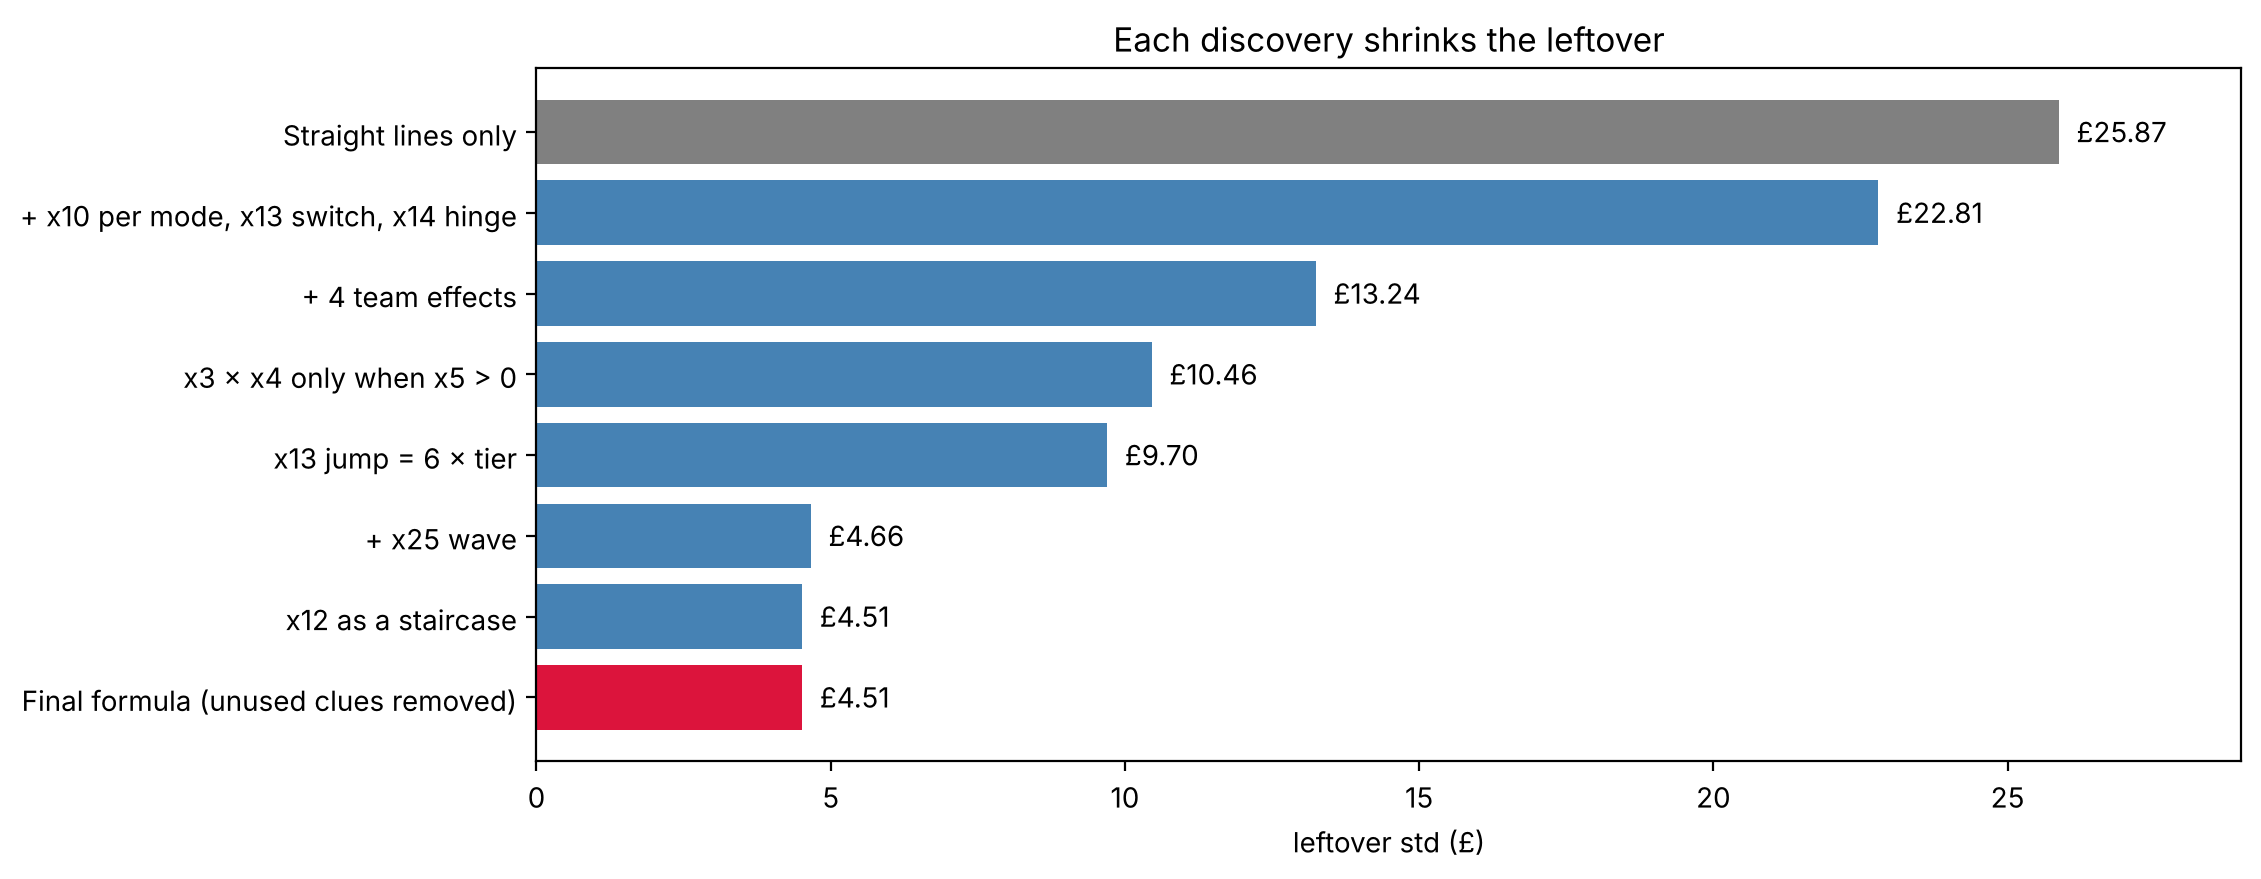

In [23]:
board = pd.Series(scoreboard)
plt.figure(figsize=(11, 4.5))
plt.barh(board.index, board.values, color=["grey"] + ["steelblue"] * (len(board) - 2) + ["crimson"])
for i, v in enumerate(board.values):
    plt.text(v + 0.3, i, f"£{v:.2f}", va="center")
plt.gca().invert_yaxis()
plt.xlim(0, board.max() * 1.12)
plt.xlabel("leftover std (£)")
plt.title("Each discovery shrinks the leftover")
plt.show()

**How to read the output:** from about **£26** with straight lines down to about **£4.5**. The biggest single steps came from the **four team effects** (about £23 → £13) and the **hidden wave** (about £9.7 → £4.7).

### Step 3.13: Is anything left in the leftover?

If the formula is complete, the leftover should be **pure noise**: no model should be able to predict it, and it should be bell-shaped.

**What this cell does:**
1. asks LightGBM to predict the leftover from all clues (3-fold CV). If it can't beat "always 0", nothing is left.
2. draws the leftover's histogram against a bell curve
3. shows the single most extreme row

Leftover std: £4.515    after LightGBM tries to predict it: £4.526


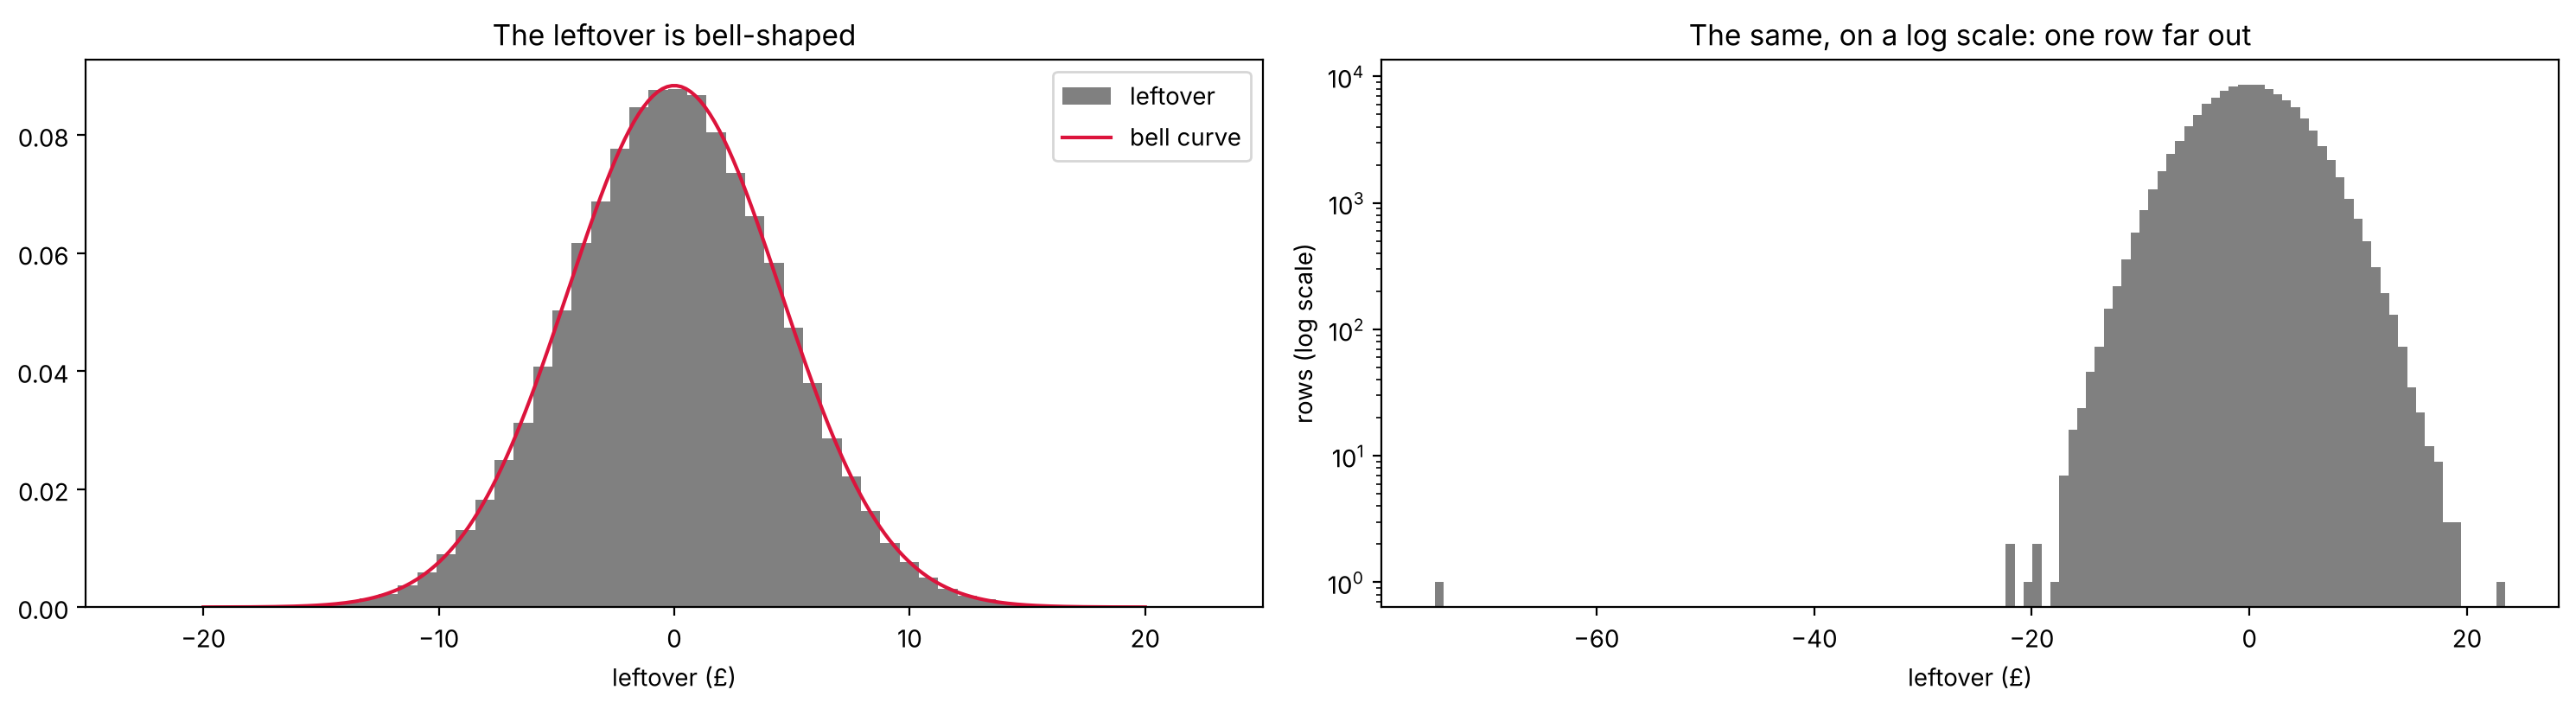

Most extreme row: leftover £-74.85


,x3,x4,x5,mode,tier,prefix,price
41010,-2.5166,1.9137,0.0,C,5,WXM,437.34


x3 × x4 for this row: -4.82  →  15 × x3 × x4 = £-72.24
Rows where x5 shows exactly 0.0000: 6


In [24]:
leftover_trees = Pipeline([("prep", encoder(False)), ("model", LGBMRegressor(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=0))])
predicted = cross_val_predict(leftover_trees, X, formula_leftover, cv=cv3)
print(f"Leftover std: £{formula_leftover.std():.3f}    after LightGBM tries to predict it: £{np.sqrt(np.mean((formula_leftover - predicted) ** 2)):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].hist(formula_leftover, bins=120, density=True, color="grey", label="leftover")
grid = np.linspace(-20, 20, 200)
axes[0].plot(grid, stats.norm.pdf(grid, 0, formula_leftover.std()), color="crimson", label="bell curve")
axes[0].set_xlim(-25, 25); axes[0].set_xlabel("leftover (£)"); axes[0].legend(); axes[0].set_title("The leftover is bell-shaped")
axes[1].hist(formula_leftover, bins=120, color="grey", log=True)
axes[1].set_xlabel("leftover (£)"); axes[1].set_ylabel("rows (log scale)"); axes[1].set_title("The same, on a log scale: one row far out")
plt.tight_layout()
plt.show()

worst = formula_leftover.abs().idxmax()
print(f"Most extreme row: leftover £{formula_leftover[worst]:.2f}")
display(train.loc[[worst], ["x3", "x4", "x5", "mode", "tier", "prefix", "price"]])
print(f"x3 × x4 for this row: {train.loc[worst, 'x3'] * train.loc[worst, 'x4']:.2f}  →  15 × x3 × x4 = £{15 * train.loc[worst, 'x3'] * train.loc[worst, 'x4']:.2f}")
print(f"Rows where x5 shows exactly 0.0000: {(train['x5'] == 0).sum()}")

**How to read the output**

* LightGBM **can't** predict the leftover: its error is about the same as the leftover itself (slightly worse, in fact). **Nothing learnable is left.**
* The histogram matches the bell curve, with a std of about **£4.5**. That's the noise: no model can do better.
* One row is about **£75** too low. Look at it: **x5 = 0.0000** and x3 × x4 = −4.82. The data is rounded to 4 decimals, so this row's real x5 was a tiny number like +0.00003 that was **rounded to 0**. The switch was really **on**, and 15 × (−4.82) = **−£72** explains the whole gap. It's not a broken row, it's a rounding accident at the switch. Only 6 rows show x5 = 0.0000, so we leave them in.

> **✅ Checkpoint. The formula:**
>
> **price = level of the prefix**
> **+ 12·x10 (mode A) / −12·x10 (mode B) / 3.6·x10 (mode C)**
> **+ 8·x11 + 8·stair(x12) + 25·sin(x1 + x2) + 15·x3·x4 (only when x5 > 0)**
> **+ 30·exp(−(x8² + x9²)) + 10·|x6 − x7| + 6·tier (only when x13 > 0.5) + 5·max(x14, 0)²**
> **+ a wave of size 12 and length 6.4 in x25**
> **+ bell-shaped noise (std £4.5)**
>
> x15–x22 do nothing, and x23, x24 are only noisy copies.

---
# Part 4: Test 12 models

### Step 4.1: The fair-test setup and the stress test

With 120,000 rows, tuning 12 models on everything would take a long time. So each model is **tuned on a random sample of 30,000 rows** with 3-fold cross-validation, and then **retrained on all 120,000 rows** to price the test row.

Normal cross-validation only checks rows **like** the training data. Our test row breaks the pattern between the clues (Step 2.6), so we add a **stress test**:

1. train each model only on the **80% most ordinary rows** of the sample (smallest pattern distance)
2. predict the **1% most unusual rows** of the whole dataset (largest pattern distance), which the model has never seen
3. measure the error on those rows. A model that uses each clue **directly** should stay close to its normal error. A model that leans on **shortcuts between clues** will get worse.

**What this cell does:** draws the sample and marks the ordinary and the unusual rows.

In [25]:
rng = np.random.default_rng(0)
in_sample = np.sort(rng.choice(len(train), 30000, replace=False))
X_sample, y_sample = X.iloc[in_sample], y.iloc[in_sample]

ordinary = dist_train < np.quantile(dist_train, 0.80)
unusual = dist_train > np.quantile(dist_train, 0.99)
ordinary_sample = ordinary[in_sample]
print(f"Tuning sample: {len(X_sample):,} rows    ordinary rows in it: {ordinary_sample.sum():,}    unusual rows (whole data): {unusual.sum():,}")
print(f"Pattern distance² of the unusual rows: {dist_train[unusual].min():.1f} to {dist_train[unusual].max():.1f}   (test row {dist_test:.1f})")

Tuning sample: 30,000 rows    ordinary rows in it: 24,026    unusual rows (whole data): 1,200
Pattern distance² of the unusual rows: 43.0 to 66.7   (test row 108.5)


### Step 4.2: The 12 models

| Family | Model | How it works, in one line |
|---|---|---|
| Straight line | Linear regression, Lasso | Best straight line through all clues and groups |
| Curves | Polynomial + Ridge | Every square and pair product of the 25 clues, shrunk |
| Curves | Spline curves + Ridge | One smooth curve per clue (Step 3.2) |
| Distance | KNN | Averages the prices of the most similar rows |
| Trees | Random forest, HistGB, XGBoost, LightGBM | Many decision trees |
| Neural network | MLP | Layers of "neurons" |
| **Formula** | **Our formula** | The ingredients from Part 3, weights found by linear regression |
| Trees + formula | LightGBM + formula columns | LightGBM, also given our ingredients as ready-made clues |

**What this cell does:** lists each model with the settings to try. GridSearchCV tries every setting; RandomizedSearchCV tries 6 random combinations (for the boosting models, which have many settings).

In [26]:
def formula_plus_clues(d):
    # our ingredients plus the raw clues, for the LightGBM + formula columns model
    return pd.concat([formula_clues(d).drop(columns=["x11"]), d[xs]], axis=1)

polynomial = ColumnTransformer([("numbers", Pipeline([("poly", PolynomialFeatures(2, include_bias=False)), ("scale", StandardScaler())]), xs),
                                ("groups", OneHotEncoder(drop="first", handle_unknown="ignore"), ["prefix", "mode", "tier"])])
splines = ColumnTransformer([("numbers", SplineTransformer(n_knots=10, degree=3), xs),
                             ("groups", OneHotEncoder(drop="first", handle_unknown="ignore"), ["prefix", "mode", "tier"])])

boost_settings = {"model__n_estimators": [300, 600, 1000], "model__learning_rate": [0.03, 0.05, 0.1],
                  "model__subsample": [0.8, 1.0], "model__colsample_bytree": [0.5, 0.8, 1.0]}

grid_models = {
    "Linear regression": (Pipeline([("prep", encoder()), ("model", LinearRegression())]), {}),
    "Lasso": (Pipeline([("prep", encoder()), ("model", Lasso(max_iter=5000))]), {"model__alpha": [0.01, 0.1, 1.0]}),
    "Polynomial + Ridge": (Pipeline([("prep", polynomial), ("model", Ridge())]), {"model__alpha": [1, 100]}),
    "Spline curves + Ridge": (Pipeline([("prep", splines), ("model", Ridge())]), {"model__alpha": [0.1, 10]}),
    "KNN": (Pipeline([("prep", encoder()), ("model", KNeighborsRegressor())]), {"model__n_neighbors": [10, 30]}),
    "Random forest": (Pipeline([("prep", encoder(False)),
                                ("model", RandomForestRegressor(n_estimators=100, max_features=0.5, max_samples=0.25, random_state=0, n_jobs=1))]),
                      {"model__min_samples_leaf": [3, 10]}),
    "HistGB": (Pipeline([("prep", encoder(False)), ("model", HistGradientBoostingRegressor(max_iter=600, random_state=0))]),
               {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31]}),
    "Neural network (MLP)": (Pipeline([("prep", encoder()), ("model", MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=100, early_stopping=True, random_state=0))]),
                             {"model__alpha": [0.0001, 0.01]}),
    "Formula": (Pipeline([("formula", FunctionTransformer(formula_clues)), ("model", LinearRegression())]), {}),
}
random_models = {
    "XGBoost": (Pipeline([("prep", encoder(False)), ("model", XGBRegressor(random_state=0, n_jobs=1))]),
                {**boost_settings, "model__max_depth": [4, 6, 8], "model__min_child_weight": [1, 10]}),
    "LightGBM": (Pipeline([("prep", encoder(False)), ("model", LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1))]),
                 {**boost_settings, "model__num_leaves": [15, 31, 63], "model__min_child_samples": [20, 50]}),
    "LightGBM + formula columns": (Pipeline([("add", FunctionTransformer(formula_plus_clues)),
                                             ("model", LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1))]),
                                   {**boost_settings, "model__num_leaves": [15, 31, 63], "model__min_child_samples": [20, 50]}),
}
print("Models ready:", list(grid_models) + list(random_models))

Models ready: ['Linear regression', 'Lasso', 'Polynomial + Ridge', 'Spline curves + Ridge', 'KNN', 'Random forest', 'HistGB', 'Neural network (MLP)', 'Formula', 'XGBoost', 'LightGBM', 'LightGBM + formula columns']


### Step 4.3: Run the contest

**What this cell does:** for each model, it
1. tries the settings with 3-fold cross-validation on the 30,000-row sample and keeps the best
2. runs the **stress test**: the same model and settings, trained on the ordinary rows of the sample, then scored on the 1% most unusual rows
3. retrains on all 120,000 rows and prices the test row

It takes about 7 minutes on 2 cores (less on a laptop with more cores).

In [27]:
results = []
contest_start = time.time()

def record(name, search):
    best_model = search.best_estimator_
    stressed = clone(best_model).fit(X_sample[ordinary_sample], y_sample[ordinary_sample])     # ordinary rows only
    miss = y[unusual].values - stressed.predict(X[unusual])                                     # misses on the unusual rows
    full = clone(best_model).fit(X, y)                                                          # all 120,000 rows
    results.append({
        "model": name,
        "CV RMSE (£)": round(-search.best_score_, 2),
        "stress RMSE on unusual rows (£)": round(float(np.sqrt(np.mean(miss ** 2))), 2),
        "test price (£)": round(float(full.predict(X_test)[0]), 2),
    })
    print(f"{name} done ({time.time() - contest_start:.0f}s)")

for name, (pipe, settings) in grid_models.items():
    search = GridSearchCV(pipe, settings, cv=cv3, scoring="neg_root_mean_squared_error", n_jobs=-1)
    record(name, search.fit(X_sample, y_sample))

for name, (pipe, settings) in random_models.items():
    search = RandomizedSearchCV(pipe, settings, n_iter=6, cv=cv3, random_state=0, scoring="neg_root_mean_squared_error", n_jobs=-1)
    record(name, search.fit(X_sample, y_sample))

results = pd.DataFrame(results).sort_values("CV RMSE (£)").reset_index(drop=True)
results["stress ÷ CV"] = (results["stress RMSE on unusual rows (£)"] / results["CV RMSE (£)"]).round(2)
results

Linear regression done (2s)


Lasso done (4s)


Polynomial + Ridge done (8s)


Spline curves + Ridge done (11s)


KNN done (14s)


Random forest done (92s)


... (3 outputs left out)

XGBoost done (280s)


LightGBM done (321s)


LightGBM + formula columns done (384s)


,model,CV RMSE (£),stress RMSE on unusual rows (£),test price (£),stress ÷ CV
0,Formula,4.51,4.29,573.39,0.95
1,LightGBM + formula columns,5.85,10.77,572.08,1.84
2,LightGBM,11.75,16.88,565.35,1.44
3,HistGB,11.92,17.47,564.23,1.47
4,XGBoost,12.01,16.83,566.90,1.40
5,Neural network (MLP),16.16,27.60,559.55,1.71
6,Spline curves + Ridge,21.07,31.68,577.26,1.50
7,Polynomial + Ridge,22.14,33.53,551.05,1.51
8,Random forest,22.28,32.06,562.09,1.44
9,Lasso,25.88,36.93,562.24,1.43


**How to read the output**

| Column | Meaning |
|---|---|
| CV RMSE | The usual score on rows like the training data |
| stress RMSE | The error on the 1% most unusual rows, after training on ordinary rows only |
| stress ÷ CV | How much worse a model gets on unusual rows. **About 1 = it doesn't care about the broken pattern.** |
| test price | The model's price for the real test row (trained on all rows) |

### Step 4.4: The scores side by side

**What this cell does:** draws CV RMSE, stress RMSE and the test price for every model.

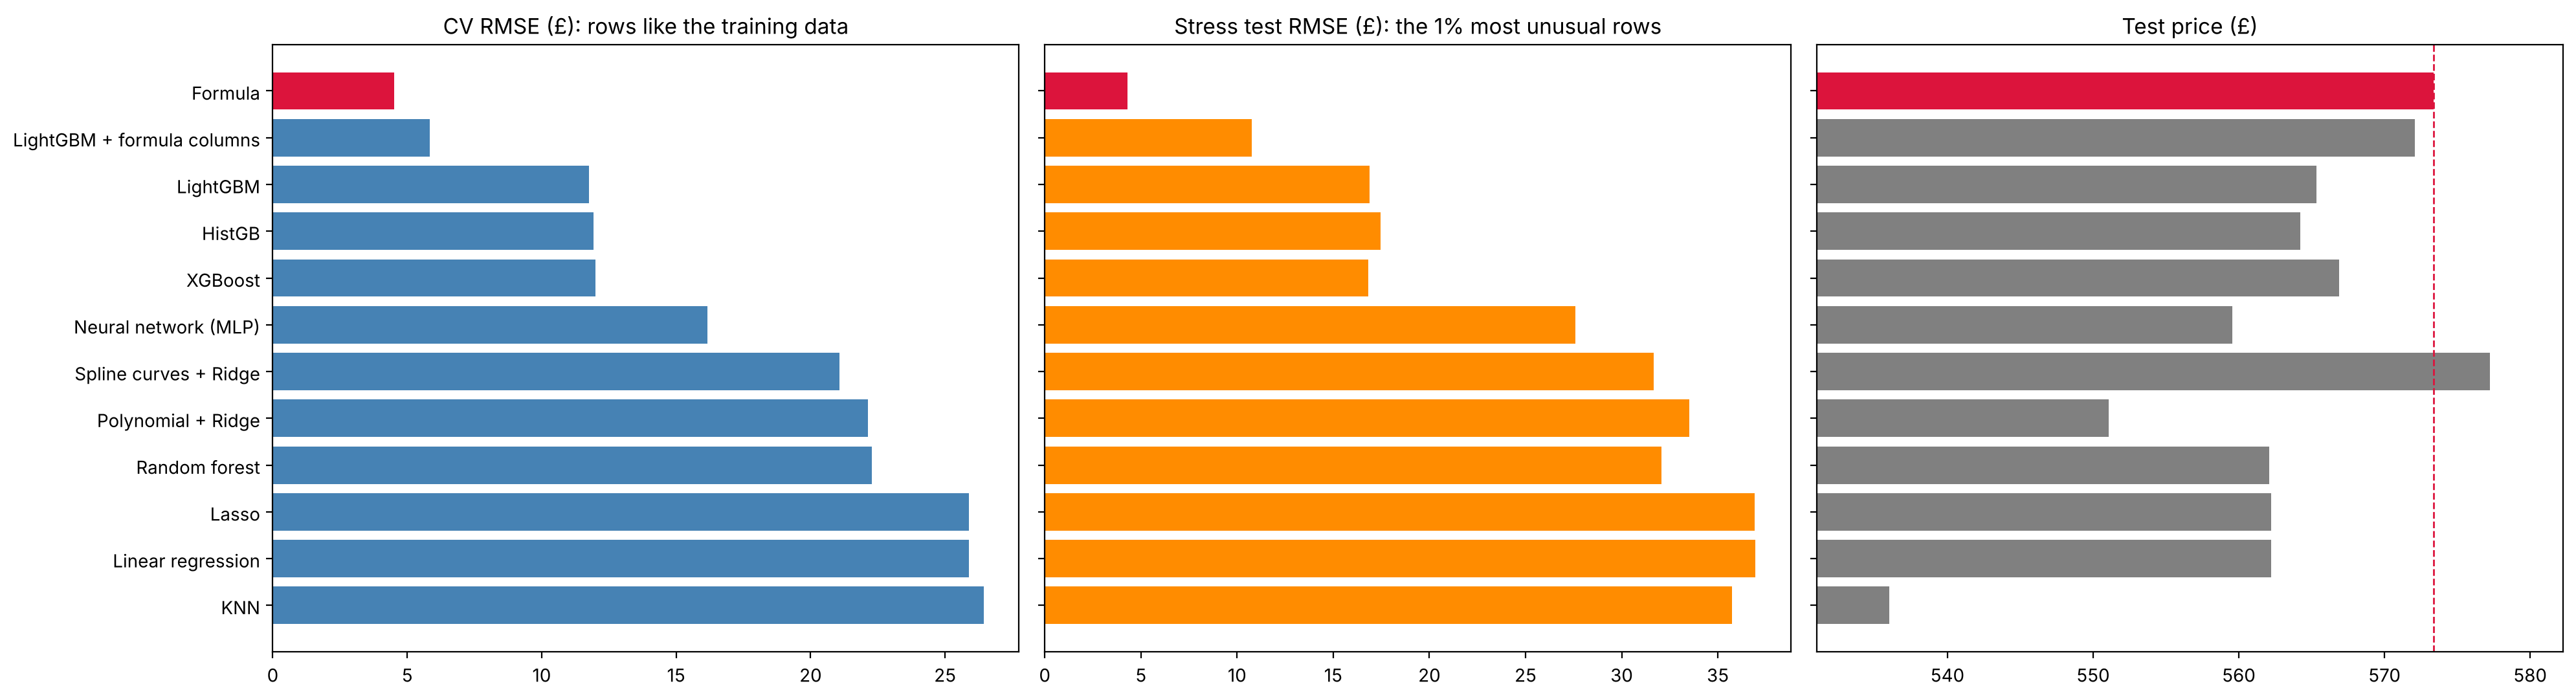

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
axes[0].barh(results["model"], results["CV RMSE (£)"], color=["crimson" if m == "Formula" else "steelblue" for m in results["model"]])
axes[0].set_title("CV RMSE (£): rows like the training data")
axes[0].invert_yaxis()
axes[1].barh(results["model"], results["stress RMSE on unusual rows (£)"], color=["crimson" if m == "Formula" else "darkorange" for m in results["model"]])
axes[1].set_title("Stress test RMSE (£): the 1% most unusual rows")
axes[2].barh(results["model"], results["test price (£)"], color=["crimson" if m == "Formula" else "grey" for m in results["model"]])
axes[2].set_xlim(results["test price (£)"].min() - 5, results["test price (£)"].max() + 5)
axes[2].axvline(results.set_index("model").loc["Formula", "test price (£)"], color="crimson", linestyle="--", linewidth=1)
axes[2].set_title("Test price (£)")
plt.tight_layout()
plt.show()

**How to read Steps 4.3 and 4.4**

* **The formula** has the best CV RMSE (about **£4.5**, the noise level) and **passes the stress test**: on the most unusual rows it is just as accurate (about £4.3). Test price: **about £573.39**.
* **LightGBM + formula columns** is second (about £5.9), but even with our ingredients handed to it, it gets almost **twice as bad** on the unusual rows (about £10.8). Its test price, about £572.1, is close to the formula's.
* **The plain tree models** (LightGBM, XGBoost, HistGB) are wrong by about **£12** on normal rows and about **£17** on unusual rows. They all price the test row at about **£564–567**, roughly **£6.5–9 too low**, mostly because a tree can't learn a wave that repeats 156 times (Step 3.8).
* The **neural network** (about £16) is worse than the trees, gets much worse on the unusual rows (about £28) and prices the test row at about £560.
* **Straight lines, polynomial, splines, random forest and KNN** are wrong by **£21–26**. They can't build the team effects, the flip or the wave. Their test prices are spread from about £536 to £577.
* **Every model except the formula gets about 1.35–1.85 times worse on the unusual rows**, so on the test row (even more unusual) their errors will be bigger still.

> **✅ Checkpoint.** Only the formula is both accurate (£4.5) and reliable when the pattern between the clues breaks. **Most other models will price this stock too low** (about £564–567 for trees).

---
# Part 5: Look inside the final formula

### Step 5.1: The prediction, step by step

**What this cell does:** prices the test row with the formula from Step 3.11, shows each ingredient's part, and draws them as a waterfall (each bar starts where the previous one ended).

start (intercept)                      496.97
+ prefix_WXM                        +21.52
+ x10_modeB                         -15.55
+ x11                                -0.37
+ x12_stair                          -6.03
+ sin_x1_plus_x2                    +22.29
+ x3x4_if_x5_pos                    -14.87
+ bump_x8_x9                        +26.35
+ gap_x6_x7                          +3.06
+ x13_step                           +0.04
+ tier_x13_step                     +23.93
+ x14_hinge                          +4.04
+ wave (x25)                        +12.02
= prediction                         573.39


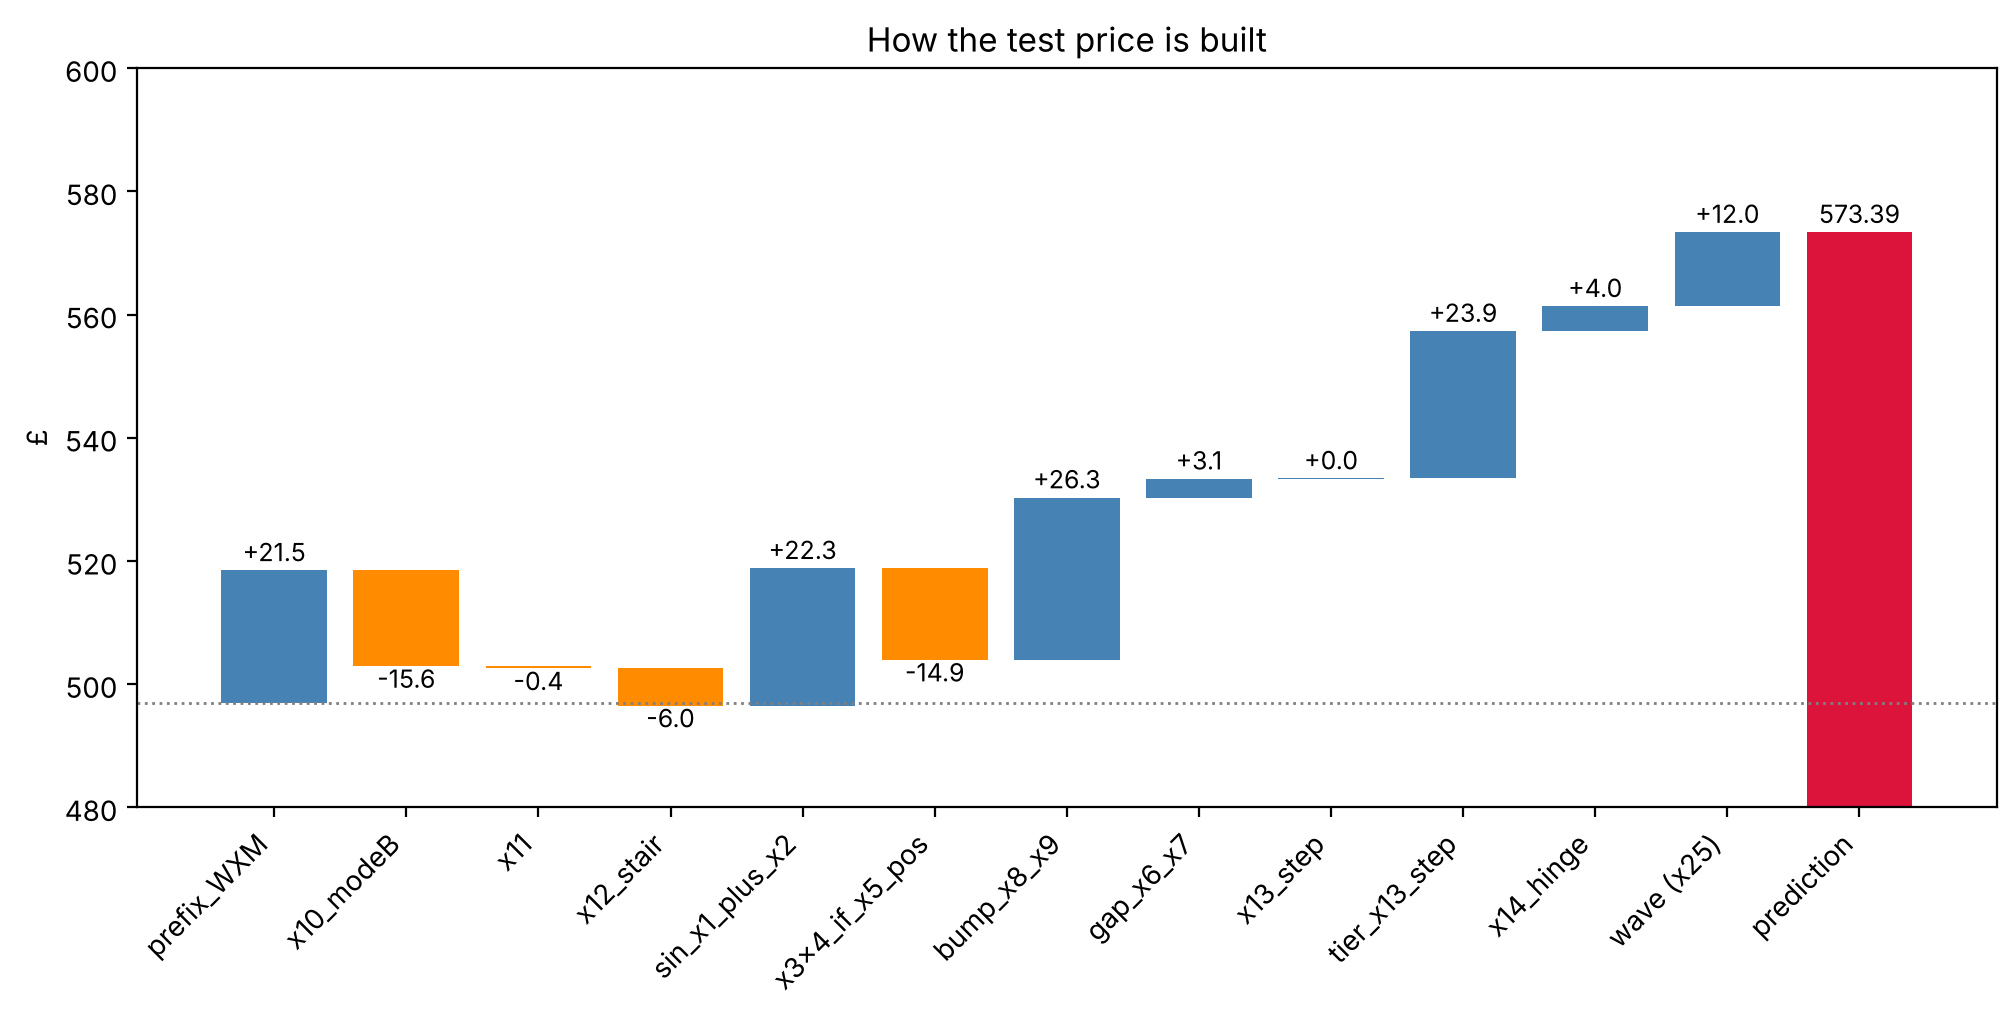

In [29]:
test_F = F_test.iloc[0]
prediction = float(formula.predict(F_test)[0])
parts = (formula_weights * test_F)
parts = parts[parts.abs() > 0.005]
wave_part = parts[["wave_sin", "wave_cos"]].sum()
parts = parts.drop(["wave_sin", "wave_cos"])
parts["wave (x25)"] = wave_part

print(f"start (intercept){'':20}{formula.intercept_:8.2f}")
for name, value in parts.items():
    print(f"+ {name:32s}{value:+8.2f}")
print(f"{'= prediction':35}{prediction:8.2f}")

running = formula.intercept_
plt.figure(figsize=(12, 4.8))
for i, (name, value) in enumerate(parts.items()):
    plt.bar(i, value, bottom=running, color="steelblue" if value > 0 else "darkorange")
    plt.text(i, running + value + (1.5 if value > 0 else -3.5), f"{value:+.1f}", ha="center", fontsize=9)
    running += value
plt.bar(len(parts), prediction, color="crimson")
plt.text(len(parts), prediction + 1.5, f"{prediction:.2f}", ha="center", fontsize=9)
plt.xticks(range(len(parts) + 1), list(parts.index) + ["prediction"], rotation=45, ha="right")
plt.ylim(480, 600)
plt.axhline(formula.intercept_, color="grey", linestyle=":", linewidth=1)
plt.ylabel("£")
plt.title("How the test price is built")
plt.show()

**How to read the output:** starting from about **£497**:

* **Up:** the bump in x8, x9 (about +26, because x8 and x9 are both near 0), the x13 jump (**+24**, tier 4), sin(x1 + x2) (about +22), the WXM prefix (about +21.5), the wave (**+12**, the top of a wave), the x14 hinge (about +4) and the gap |x6 − x7| (about +3)
* **Down:** x10 in mode B (about **−15.6**), x3 × x4 with the switch on (about **−15**) and the x12 staircase (about −6)
* **Prediction: about £573.39**

### Step 5.2: Where the test row sits on each ingredient

**What this cell does:** draws each ingredient's shape (red line), a sample of training rows with the other ingredients removed (blue dots), and the test row (black star).

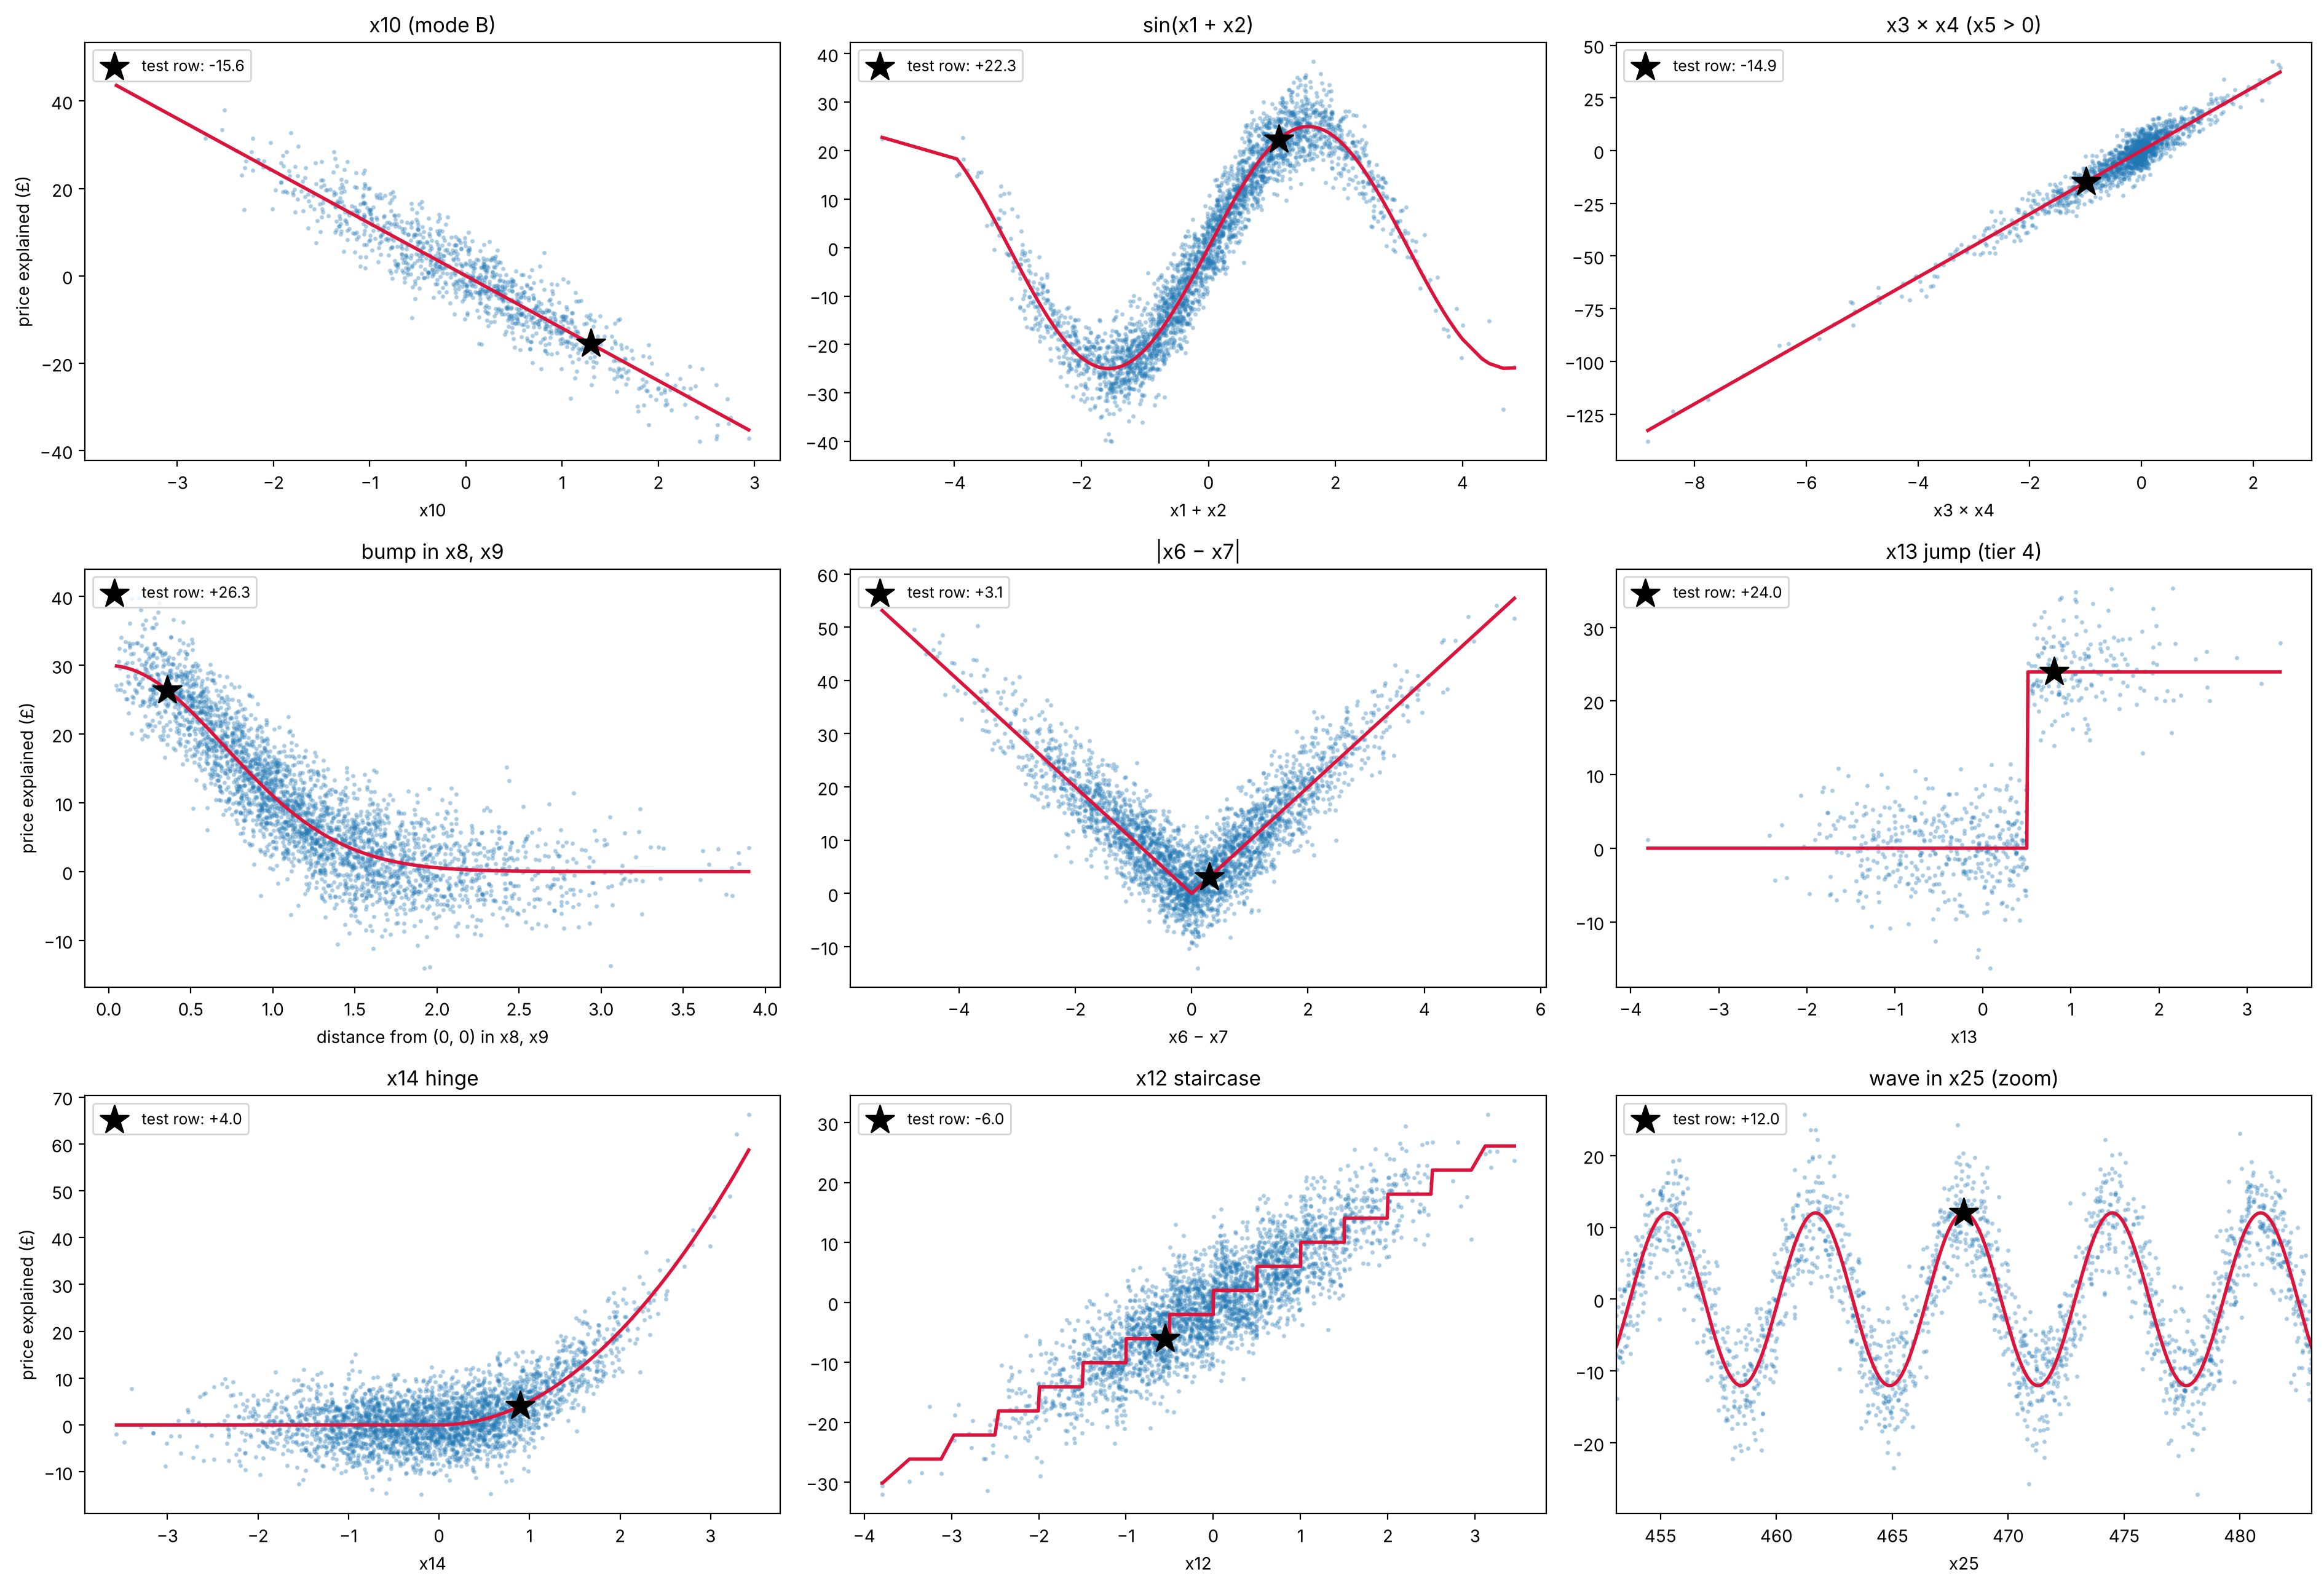

In [30]:
dots = np.random.default_rng(1).choice(len(train), 3000, replace=False)

def explained_by(columns):
    # price explained by these ingredients only: leftover + their part
    return formula_leftover + (F_train[columns] * formula_weights[columns]).sum(axis=1)

panels = [
    ("x10 (mode B)", "x10", ["x10_modeB"], train["mode"] == "B"),
    ("sin(x1 + x2)", None, ["sin_x1_plus_x2"], None),
    ("x3 × x4 (x5 > 0)", None, ["x3x4_if_x5_pos"], train["x5"] > 0),
    ("bump in x8, x9", None, ["bump_x8_x9"], None),
    ("|x6 − x7|", None, ["gap_x6_x7"], None),
    ("x13 jump (tier 4)", "x13", ["x13_step", "tier_x13_step"], train["tier"] == 4),
    ("x14 hinge", "x14", ["x14_hinge"], None),
    ("x12 staircase", "x12", ["x12_stair"], None),
    ("wave in x25 (zoom)", "x25", ["wave_sin", "wave_cos"], None),
]
along = {"sin(x1 + x2)": train["x1"] + train["x2"], "x3 × x4 (x5 > 0)": train["x3"] * train["x4"],
         "bump in x8, x9": np.sqrt(train["x8"] ** 2 + train["x9"] ** 2), "|x6 − x7|": train["x6"] - train["x7"]}
along_test = {"sin(x1 + x2)": test["x1"].item() + test["x2"].item(), "x3 × x4 (x5 > 0)": test["x3"].item() * test["x4"].item(),
              "bump in x8, x9": np.hypot(test["x8"].item(), test["x9"].item()), "|x6 − x7|": test["x6"].item() - test["x7"].item()}
x_labels = {"sin(x1 + x2)": "x1 + x2", "x3 × x4 (x5 > 0)": "x3 × x4", "bump in x8, x9": "distance from (0, 0) in x8, x9", "|x6 − x7|": "x6 − x7"}

fig, axes = plt.subplots(3, 3, figsize=(19, 13))
for ax, (title, clue, columns, keep) in zip(axes.ravel(), panels):
    keep = np.ones(len(train), dtype=bool) if keep is None else keep.values
    xv = (train[clue] if clue else along[title]).values
    xt = test[clue].item() if clue else along_test[title]
    yv = explained_by(columns).values
    curve = (F_train[columns] * formula_weights[columns]).sum(axis=1).values
    yt = float((F_test[columns].iloc[0] * formula_weights[columns]).sum())
    if clue == "x25":
        rows = np.where(keep & (np.abs(xv - xt) < 15))[0][:2000]      # zoom: rows within 15 units of the test row
        ax.set_xlim(xt - 15, xt + 15)
    else:
        rows = np.intersect1d(dots, np.where(keep)[0])
    order = rows[np.argsort(xv[rows])]
    ax.scatter(xv[rows], yv[rows], s=3, alpha=0.25)
    ax.plot(xv[order], curve[order], color="crimson", linewidth=2)
    ax.scatter([xt], [yt], marker="*", s=300, color="black", zorder=5, label=f"test row: {yt:+.1f}")
    ax.set_title(title); ax.set_xlabel(x_labels.get(title, clue)); ax.legend(loc="upper left", fontsize=9)
axes[0, 0].set_ylabel("price explained (£)"); axes[1, 0].set_ylabel("price explained (£)"); axes[2, 0].set_ylabel("price explained (£)")
plt.tight_layout()
plt.show()

**How to read the output:** in every panel the black star sits **on the red line and inside the cloud of training rows**. Each ingredient, taken alone, is in familiar territory for the test row:

* **x10 (mode B)**: a falling line, the test row is at +1.30 → about −15.6
* **sin(x1 + x2)**: x1 + x2 = 1.10, near the top of the wave → about +22
* **x3 × x4**: −0.99 with the switch on → about −15
* **bump**: the test row is only about 0.36 from (0, 0), so it gets most of the bump → about +26
* **x13 jump**: above 0.5 in tier 4 → +24
* **x12 staircase**: −0.553 falls in the −0.75 step → about −6
* **wave**: x25 = 468.09 sits right on a crest → about +12

So even though the test row's **combination** of clues is new, **no ingredient has to be extended beyond the data**. That's why the formula's price is trustworthy here, while the models that learned shortcuts between clues are not.

> **✅ Checkpoint.** Prediction **£573.39**, built from ingredients that are all inside their training range.

---
# Part 6: How sure are we?

### Step 6.1: Model error (bootstrap)

**What this cell does:** retrains the formula 200 times on random rows (some twice, some not at all) and prices the test row each time. The spread of those prices is the **model error**.

In [31]:
rng = np.random.default_rng(0)
boot = []
for b in range(200):
    rows_b = rng.integers(0, len(train), len(train))
    model_b = LinearRegression().fit(F_train.iloc[rows_b], y.iloc[rows_b])
    boot.append(float(model_b.predict(F_test)[0]))
boot = np.array(boot)

noise = formula_leftover.std()
sigma = np.sqrt(boot.std() ** 2 + noise ** 2)
inside_1 = (formula_leftover.abs() < noise).mean()
inside_2 = (formula_leftover.abs() < 2 * noise).mean()
print(f"Model error (bootstrap spread): £{boot.std():.3f}")
print(f"Noise (leftover std):           £{noise:.3f}")
print(f"Total uncertainty:              £{sigma:.3f}")
print(f"Share of training rows within ±1 std: {inside_1:.1%}  (bell curve: 68.3%)   within ±2 std: {inside_2:.1%}  (bell curve: 95.4%)")
print(f"68% range: £{prediction - sigma:.2f} to £{prediction + sigma:.2f}    95% range: £{prediction - 1.96 * sigma:.2f} to £{prediction + 1.96 * sigma:.2f}")

Model error (bootstrap spread): £0.068
Noise (leftover std):           £4.515
Total uncertainty:              £4.515
Share of training rows within ±1 std: 68.4%  (bell curve: 68.3%)   within ±2 std: 95.5%  (bell curve: 95.4%)
68% range: £568.88 to £577.91    95% range: £564.54 to £582.24


**How to read the output:** with 120,000 rows, every weight is measured so precisely that the model moves by only about **7p** between bootstraps. Almost all the uncertainty is **noise**, about **£4.5**, and it behaves like a bell curve (about 68% of rows within ±1 std and 95% within ±2 std). So the usual 1/2/3 std ranges are trustworthy.

### Step 6.2: What will other teams say?

Each trap in this stock pushes the price a different way. **What this cell does:** refits the formula **without** one discovery at a time, and collects the contest's prices for typical models.

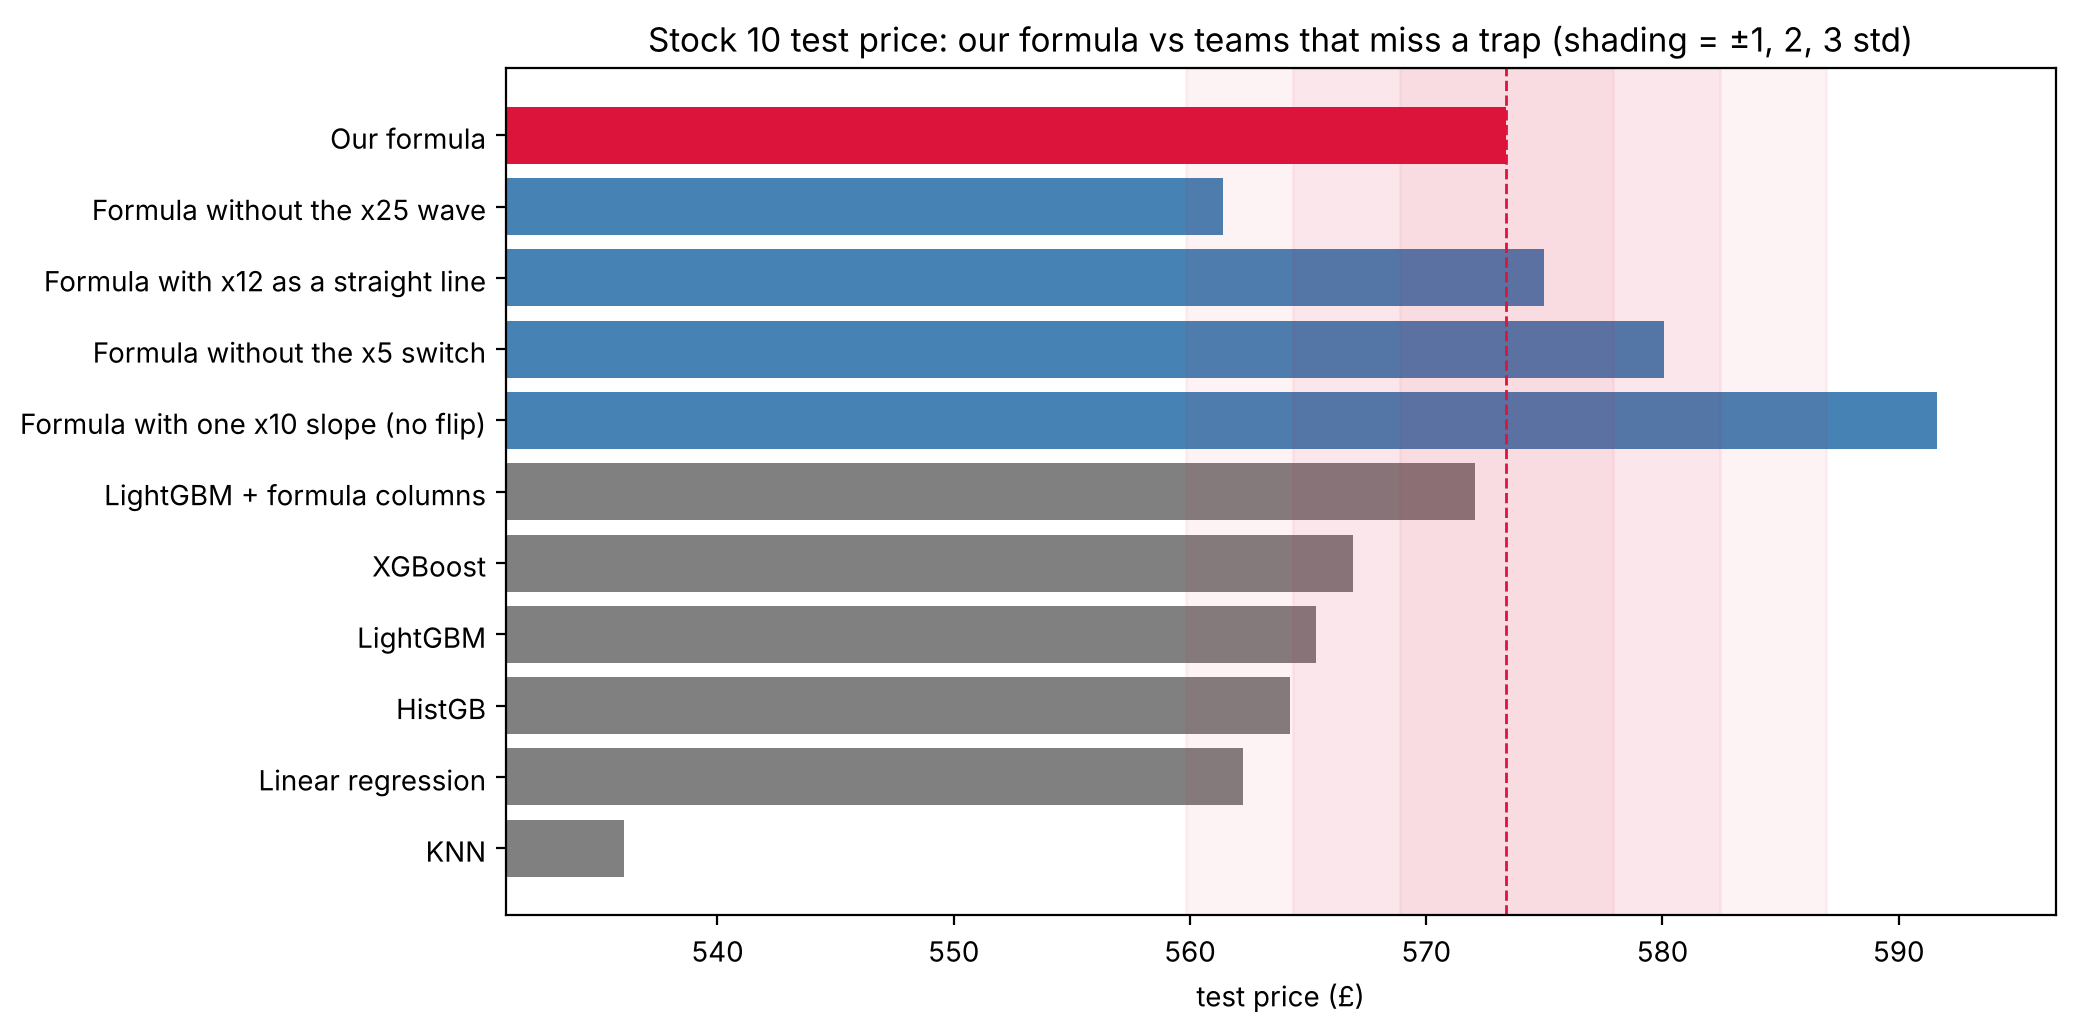

,test price (£)
Our formula,573.39
Formula without the x25 wave,561.40
Formula with x12 as a straight line,574.97
Formula without the x5 switch,580.08
Formula with one x10 slope (no flip),591.64
LightGBM + formula columns,572.08
XGBoost,566.90
LightGBM,565.35
HistGB,564.23
Linear regression,562.24


In [32]:
def without(drop, add=None):
    F_tr, F_te = F_train.drop(columns=drop), F_test.drop(columns=drop)
    if add is not None:
        for name, (tr_col, te_col) in add.items():
            F_tr[name], F_te[name] = tr_col, te_col
    return float(LinearRegression().fit(F_tr, y).predict(F_te)[0])

contest = results.set_index("model")["test price (£)"]
scenarios = pd.Series({
    "Our formula": prediction,
    "Formula without the x25 wave": without(["wave_sin", "wave_cos"]),
    "Formula with x12 as a straight line": without(["x12_stair"], {"x12": (train["x12"], test["x12"])}),
    "Formula without the x5 switch": without(["x3x4_if_x5_pos"], {"x3*x4": (train["x3"] * train["x4"], test["x3"] * test["x4"])}),
    "Formula with one x10 slope (no flip)": without(["x10_modeA", "x10_modeB", "x10_modeC"], {"x10": (train["x10"], test["x10"])}),
    "LightGBM + formula columns": contest["LightGBM + formula columns"],
    "XGBoost": contest["XGBoost"],
    "LightGBM": contest["LightGBM"],
    "HistGB": contest["HistGB"],
    "Linear regression": contest["Linear regression"],
    "KNN": contest["KNN"],
}).round(2)

plt.figure(figsize=(10, 5.5))
plt.barh(scenarios.index, scenarios.values, color=["crimson"] + ["steelblue"] * 4 + ["grey"] * 6)
plt.axvline(prediction, color="crimson", linestyle="--", linewidth=1)
for k in [1, 2, 3]:
    plt.axvspan(prediction - k * sigma, prediction + k * sigma, color="crimson", alpha=0.05)
plt.gca().invert_yaxis()
plt.xlim(scenarios.min() - 5, scenarios.max() + 5); plt.xlabel("test price (£)")
plt.title("Stock 10 test price: our formula vs teams that miss a trap (shading = ±1, 2, 3 std)")
plt.show()
scenarios.to_frame("test price (£)")

**How to read the output**

* **Missing the wave** is the most likely mistake (x25 has correlation 0): it gives about **£561**, about **£12 too low**.
* **Missing the x10 flip** gives about **£592**, about **£18 too high**, because x10 then pushes the price **up** for mode B.
* **Missing the x5 switch** gives about **£580** (about £7 too high), and treating **x12 as a straight line** gives about £575 (about £1.6 too high).
* **Tree models** say about **£564–567** (too low, by about 1.5–2 std). Linear regression says about £562, KNN about £536.

So **most teams will be too low**, and a few (those who miss the flip or the switch) too high.

> **✅ Checkpoint.** Price **£573.39 ± £4.52**. The uncertainty is almost all noise. Most other teams will say about £561–567.

---
# Part 7: Make a quote and a trading plan

### Step 7.1: Quote options

**What this cell does:** prints quotes for 1, 2 and 3 std of the total uncertainty.

In [33]:
centre = prediction
for k in [1, 2, 3]:
    print(f"±{k} std:  bid £{centre - k * sigma:.2f}   ask £{centre + k * sigma:.2f}   (spread £{2 * k * sigma:.2f})")

±1 std:  bid £568.88   ask £577.91   (spread £9.03)
±2 std:  bid £564.36   ask £582.42   (spread £18.06)
±3 std:  bid £559.85   ask £586.94   (spread £27.09)


### Step 7.2: Market maker or trader?

* Our formula explains **everything except pure noise**, and the noise is a clean bell curve. Unlike stock 8, there is **no extrapolation risk**: every ingredient is inside its training range for the test row.
* **Most teams will be too low** (about £561–567). If one of them is market maker, its **ask** will be below our centre, and we **buy**.
* **If we are market maker** with a tight quote (±1 std: bid about £568.88, ask about £577.91), those teams will think our bid is generous and **sell to us** at £568.88. If the price settles near £573.39, we make about £4.50 per share.

**Suggestion:** this is a stock where it pays to be **confident**. Quote **±1 std** (or ±1.5 std if you want a safety margin). If another team wins the market-maker seat, trade against its quote using the table below.

### Step 7.3: Trading plan

You buy at the market maker's **ask** and sell at its **bid**. Compare them with our centre (**£573.39**, 1 std = **£4.52**):

| Market maker's prices | What we do | Size |
|---|---|---|
| **Ask below about £559.85** (more than 3 std under) | **Buy** | **Maximum** |
| Ask between about £559.85 and £564.36 (2–3 std under) | Buy | Big |
| Ask between about £564.36 and £568.88 (1–2 std under) | Buy | Medium |
| Ask between about £568.88 and £573.39 | Buy | Small |
| Bid between about £573.39 and £577.91 | Sell | Small |
| Bid between about £577.91 and £582.42 (1–2 std over) | Sell | Medium |
| Bid between about £582.42 and £586.94 (2–3 std over) | Sell | Big |
| **Bid above about £586.94** (more than 3 std over) | **Sell** | **Maximum** |

**Likely scenarios:**
* Market maker **missed the wave** (mid about £561) → ask about £561–565 → **buy big**.
* Market maker used **trees** (mid about £564–567) → **buy medium to big**.
* Market maker **missed the x5 switch** (mid about £580) → bid about £576–578 → **sell small to medium**.
* Market maker **missed the x10 flip** (mid about £592) → bid well above £586.94 → **sell the maximum**.
* Market maker found the formula (mid about £573) → no edge, trade the minimum.

---

### Lessons so far

| Stock | Trap | What we did |
|---|---|---|
| 1 | None (warm-up) | Linear regression, quote ±1–2 std |
| 2 | Few rows, extreme test row | Wide quote (±£15), stay a trader |
| 3 | Out-of-range **decoy** clue | Checked it has no effect, removed it |
| 4 | Missing near-copy of the price, noise that depends on x5 | Dropped x7, measured the noise where the test row lives |
| 5 | Missing value + rare sector | Flag for missing x3, a separate x1 weight per sector |
| 7 | Prices in pence, a team effect, jumpy noise | Cleaned prices, found x5 × x6, used real miss ranges |
| 8 | Hidden file, team effect, extreme test row | Joined m1/m2, found x2 × x3, stress-tested extrapolation, priced the bend risk |
| 10 | **A flip by mode, team effects, switches, a staircase, a hidden wave, a test row that breaks the clue pattern** | Mode-split slopes, pair maps, a wave scan, a pattern-distance stress test |

> **✅ Final checkpoint.** Stock 10 price **£573.39 ± £4.52**. The formula explains everything except bell-shaped noise. Most other teams will be **too low** (about £561–567), so **buy from them**, or make a tight market.